In [256]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
print("successfull")

successfull


#Step 1
Understand the existing data
Our main dataset is:

data/propagated_debris.csv

It contains predicted positions and velocities of space objects generated by Member 3's orbital propagation script.

In [257]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("propagated_debris.csv")
print(df.head(10))

   NORAD_CAT_ID      OBJECT_NAME               ELEMENT_EPOCH  \
0         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
1         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
2         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
3         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
4         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
5         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
6         33757  COSMOS 2251 DEB  2026-10-21T06:16:48.277632   
7         33758  COSMOS 2251 DEB  2026-10-21T03:27:58.309632   
8         33758  COSMOS 2251 DEB  2026-10-21T03:27:58.309632   
9         33758  COSMOS 2251 DEB  2026-10-21T03:27:58.309632   

                PREDICTION_TIME_UTC  MINUTES_FROM_START    X_TEME_KM  \
0  2026-10-26T07:14:37.419912+00:00                   0  2541.523356   
1  2026-10-26T07:24:37.419912+00:00                  10  1819.703220   
2  2026-10-26T07:34:37.419912+00:00                  20   416.269933   
3  2026

In [258]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(4060, 11)


In [259]:
print("Column names:")
print(df.columns.tolist())

Column names:
['NORAD_CAT_ID', 'OBJECT_NAME', 'ELEMENT_EPOCH', 'PREDICTION_TIME_UTC', 'MINUTES_FROM_START', 'X_TEME_KM', 'Y_TEME_KM', 'Z_TEME_KM', 'VX_TEME_KM_S', 'VY_TEME_KM_S', 'VZ_TEME_KM_S']


In [ ]:
#Count unique space objects
print("Total unique space object:")
print(df["NORAD_CAT_ID"].nunique())

Total unique space object:
580


In [ ]:
#
print(df["MINUTES_FROM_START"].unique())

[ 0 10 20 30 40 50 60]


In [262]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 4060 entries, 0 to 4059
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   NORAD_CAT_ID         4060 non-null   int64  
 1   OBJECT_NAME          4060 non-null   str    
 2   ELEMENT_EPOCH        4060 non-null   str    
 3   PREDICTION_TIME_UTC  4060 non-null   str    
 4   MINUTES_FROM_START   4060 non-null   int64  
 5   X_TEME_KM            4060 non-null   float64
 6   Y_TEME_KM            4060 non-null   float64
 7   Z_TEME_KM            4060 non-null   float64
 8   VX_TEME_KM_S         4060 non-null   float64
 9   VY_TEME_KM_S         4060 non-null   float64
 10  VZ_TEME_KM_S         4060 non-null   float64
dtypes: float64(6), int64(2), str(3)
memory usage: 349.0 KB
None


In [263]:
print(df.describe())

       NORAD_CAT_ID  MINUTES_FROM_START    X_TEME_KM    Y_TEME_KM  \
count   4060.000000         4060.000000  4060.000000  4060.000000   
mean   35785.603448           30.000000    -6.818084    39.021080   
std     2512.218789           20.002464  3680.974477  3698.049286   
min    33757.000000            0.000000 -7565.177768 -7540.961078   
25%    34302.750000           10.000000 -2828.076772 -2812.678096   
50%    34967.500000           30.000000   -53.795006   123.166049   
75%    36366.250000           50.000000  2752.989732  2879.410880   
max    53093.000000           60.000000  7554.620272  7681.335516   

         Z_TEME_KM  VX_TEME_KM_S  VY_TEME_KM_S  VZ_TEME_KM_S  
count  4060.000000   4060.000000   4060.000000   4060.000000  
mean    -11.229569     -0.030571      0.009697      0.111097  
std    4849.360606      3.838731      3.932332      5.076798  
min   -7668.913292     -7.613181     -7.589880     -7.383896  
25%   -4886.692756     -2.960062     -3.104311     -4.894017  


In [264]:
print(df.isnull().sum())

NORAD_CAT_ID           0
OBJECT_NAME            0
ELEMENT_EPOCH          0
PREDICTION_TIME_UTC    0
MINUTES_FROM_START     0
X_TEME_KM              0
Y_TEME_KM              0
Z_TEME_KM              0
VX_TEME_KM_S           0
VY_TEME_KM_S           0
VZ_TEME_KM_S           0
dtype: int64


In [265]:
print("total missing values", df.isnull().sum().sum())

total missing values 0


In [266]:
records_per_object = df.groupby("NORAD_CAT_ID").size()
print(records_per_object.value_counts().sort_index())

7    580
Name: count, dtype: int64


In [267]:
print("total duplicate rows")
print(df.duplicated().sum())

total duplicate rows
0


In [268]:
print("Duplicate object and prediction-time combinations:")

print(
    df.duplicated(
        subset=["NORAD_CAT_ID","PREDICTION_TIME_UTC"]
    ).sum()
)

Duplicate object and prediction-time combinations:
0


In [269]:
numeric_df = df.select_dtypes(include = np.number)

print("Non-finite values:")
print((~np.isfinite(numeric_df)).sum())

Non-finite values:
NORAD_CAT_ID          0
MINUTES_FROM_START    0
X_TEME_KM             0
Y_TEME_KM             0
Z_TEME_KM             0
VX_TEME_KM_S          0
VY_TEME_KM_S          0
VZ_TEME_KM_S          0
dtype: int64


In [270]:
#Convert prediction timestamps into datetime format
df["PREDICTION_TIME_UTC"] = pd.to_datetime(
df["PREDICTION_TIME_UTC"],
utc = True
)

# Count unique prediction timestamps
print("Unique prediction timestamps:")
print(df["PREDICTION_TIME_UTC"].nunique())

#Display all prediction timestamps
print("\nPrediction timestamps:")
print(df["PREDICTION_TIME_UTC"].drop_duplicates().sort_values())


Unique prediction timestamps:
7

Prediction timestamps:
0   2026-10-26 07:14:37.419912+00:00
1   2026-10-26 07:24:37.419912+00:00
2   2026-10-26 07:34:37.419912+00:00
3   2026-10-26 07:44:37.419912+00:00
4   2026-10-26 07:54:37.419912+00:00
5   2026-10-26 08:04:37.419912+00:00
6   2026-10-26 08:14:37.419912+00:00
Name: PREDICTION_TIME_UTC, dtype: datetime64[us, UTC]


In [271]:
# Check the number of unique timestamps for every object
timestamps_per_object = (
    df.groupby("NORAD_CAT_ID")["PREDICTION_TIME_UTC"].nunique()
)

print(timestamps_per_object.value_counts().sort_index())

PREDICTION_TIME_UTC
7    580
Name: count, dtype: int64


In [272]:
# Check prediction intervals for every object

intervals_per_object = (
    df.groupby("NORAD_CAT_ID")["MINUTES_FROM_START"]
      .apply(lambda x: sorted(x.tolist()))
)

expected_intervals = [0, 10, 20, 30, 40, 50, 60]

incorrect_objects = intervals_per_object[
    intervals_per_object.apply(lambda x: x != expected_intervals)
]

print("Objects with incorrect prediction intervals:", len(incorrect_objects))

Objects with incorrect prediction intervals: 0


In [273]:
#position and velocity ranges
print("Position ranges (km):")

position_columns = [
    "X_TEME_KM",
    "Y_TEME_KM",
    "Z_TEME_KM"
]

print(df[position_columns].agg(["min", "max"]))

print("\nVelocity ranges (km/s):")

velocity_columns = [
    "VX_TEME_KM_S",
    "VY_TEME_KM_S",
    "VZ_TEME_KM_S"
]

print(df[velocity_columns].agg(["min", "max"]))

Position ranges (km):
       X_TEME_KM    Y_TEME_KM    Z_TEME_KM
min -7565.177768 -7540.961078 -7668.913292
max  7554.620272  7681.335516  7350.358401

Velocity ranges (km/s):
     VX_TEME_KM_S  VY_TEME_KM_S  VZ_TEME_KM_S
min     -7.613181     -7.589880     -7.383896
max      7.661925      7.592885      7.347606


In [274]:
#Create a separate working DataFrame 
analysis_df = df.copy()
print("Original dataset shape",df.shape)
print("Analysis dataset shape", analysis_df.shape)

Original dataset shape (4060, 11)
Analysis dataset shape (4060, 11)


In [275]:
# Standardize column names
analysis_df.columns = analysis_df.columns.str.lower()

print(analysis_df.columns.tolist())

['norad_cat_id', 'object_name', 'element_epoch', 'prediction_time_utc', 'minutes_from_start', 'x_teme_km', 'y_teme_km', 'z_teme_km', 'vx_teme_km_s', 'vy_teme_km_s', 'vz_teme_km_s']


In [276]:
#Convert timestamps into datetime format
analysis_df["element_epoch"] = pd.to_datetime(
    analysis_df["element_epoch"],
    utc=True
)

analysis_df["prediction_time_utc"] = pd.to_datetime(
    analysis_df["prediction_time_utc"],
    utc=True
)

print("Timestamp conversion completed!")

print(analysis_df[
    ["element_epoch", "prediction_time_utc"]
].dtypes)

Timestamp conversion completed!
element_epoch          datetime64[us, UTC]
prediction_time_utc    datetime64[us, UTC]
dtype: object


In [277]:
#Verify all data types
print(analysis_df.dtypes)

norad_cat_id                         int64
object_name                            str
element_epoch          datetime64[us, UTC]
prediction_time_utc    datetime64[us, UTC]
minutes_from_start                   int64
x_teme_km                          float64
y_teme_km                          float64
z_teme_km                          float64
vx_teme_km_s                       float64
vy_teme_km_s                       float64
vz_teme_km_s                       float64
dtype: object


In [278]:
#Validate object identifiers
print("Missing object IDs:")
print(analysis_df["norad_cat_id"].isnull().sum())

print("\nZero or negative object IDs:")
print((analysis_df["norad_cat_id"] <= 0).sum())

print("\nTotal unique objects:")
print(analysis_df["norad_cat_id"].nunique())

Missing object IDs:
0

Zero or negative object IDs:
0

Total unique objects:
580


In [279]:
#Validate physical position and velocity values.
analysis_df["position_magnitude_km"] = np.sqrt(
    analysis_df["x_teme_km"]**2 +
    analysis_df["y_teme_km"]**2 +
    analysis_df["z_teme_km"]**2
)

print(analysis_df["position_magnitude_km"].describe())

count    4060.000000
mean     7120.818593
std       156.798862
min      6503.691628
25%      7037.360717
50%      7104.500428
75%      7158.504663
max      7990.181698
Name: position_magnitude_km, dtype: float64


In [280]:
analysis_df["speed_km_s"] = np.sqrt(
    analysis_df["vx_teme_km_s"]**2 +
    analysis_df["vy_teme_km_s"]**2 +
    analysis_df["vz_teme_km_s"]**2
)

print(analysis_df["speed_km_s"].describe())

count    4060.000000
mean        7.480752
std         0.104430
min         6.851671
25%         7.457336
50%         7.497206
75%         7.538233
max         7.833845
Name: speed_km_s, dtype: float64


In [281]:
#identify unusual values
low_position_records = analysis_df[
    analysis_df["position_magnitude_km"] < 6700
]

print("Records with position magnitude below 6700 km:")
print(len(low_position_records))

print("\nAffected objects:")
print(
    low_position_records[
        ["norad_cat_id", "object_name",
         "prediction_time_utc", "position_magnitude_km"]
    ]
)


Records with position magnitude below 6700 km:
14

Affected objects:
      norad_cat_id      object_name              prediction_time_utc  \
469          33939  COSMOS 2251 DEB 2026-10-26 07:14:37.419912+00:00   
470          33939  COSMOS 2251 DEB 2026-10-26 07:24:37.419912+00:00   
471          33939  COSMOS 2251 DEB 2026-10-26 07:34:37.419912+00:00   
472          33939  COSMOS 2251 DEB 2026-10-26 07:44:37.419912+00:00   
473          33939  COSMOS 2251 DEB 2026-10-26 07:54:37.419912+00:00   
474          33939  COSMOS 2251 DEB 2026-10-26 08:04:37.419912+00:00   
475          33939  COSMOS 2251 DEB 2026-10-26 08:14:37.419912+00:00   
3773         38487  COSMOS 2251 DEB 2026-10-26 07:14:37.419912+00:00   
3774         38487  COSMOS 2251 DEB 2026-10-26 07:24:37.419912+00:00   
3775         38487  COSMOS 2251 DEB 2026-10-26 07:34:37.419912+00:00   
3776         38487  COSMOS 2251 DEB 2026-10-26 07:44:37.419912+00:00   
3777         38487  COSMOS 2251 DEB 2026-10-26 07:54:37.419912+00:0

In [282]:
#inspect the two object together
review_objects = analysis_df[
    analysis_df["norad_cat_id"].isin([33939, 38487])
]

review_summary = review_objects.groupby(
    ["norad_cat_id", "object_name"]
).agg(
    total_records=("position_magnitude_km", "count"),
    min_position_km=("position_magnitude_km", "min"),
    max_position_km=("position_magnitude_km", "max"),
    min_speed_km_s=("speed_km_s", "min"),
    max_speed_km_s=("speed_km_s", "max"),
    element_epoch=("element_epoch", "first")
).reset_index()

review_summary["min_approx_altitude_km"] = (
    review_summary["min_position_km"] - 6371
)

print(review_summary)

   norad_cat_id      object_name  total_records  min_position_km  \
0         33939  COSMOS 2251 DEB              7      6503.691628   
1         38487  COSMOS 2251 DEB              7      6653.336997   

   max_position_km  min_speed_km_s  max_speed_km_s  \
0      6527.589501        7.802207        7.833845   
1      6681.917934        7.708996        7.744255   

                     element_epoch  min_approx_altitude_km  
0 2026-10-15 14:49:08.112000+00:00              132.691628  
1 2026-10-04 06:44:04.818048+00:00              282.336997  


In [283]:
#calculate orbital element age
analysis_df["element_age_hours"] = (
    analysis_df["prediction_time_utc"] -
    analysis_df["element_epoch"]
).dt.total_seconds() / 3600

print(
    analysis_df.groupby(
        ["norad_cat_id", "object_name"]
    )["element_age_hours"].first().describe()
)


count    580.000000
mean     116.848351
std       72.525905
min       73.477832
25%       82.358986
50%       93.162715
75%      119.430607
max      707.419817
Name: element_age_hours, dtype: float64


In [284]:
#check the two suspicious objects
suspicious_age = analysis_df[
    analysis_df["norad_cat_id"].isin([33939, 38487])
].groupby(
    ["norad_cat_id", "object_name"]
).agg(
    element_age_hours=("element_age_hours", "first"),
    minimum_radius_km=("position_magnitude_km", "min"),
    minimum_speed_km_s=("speed_km_s", "min")
).reset_index()

print(suspicious_age)


   norad_cat_id      object_name  element_age_hours  minimum_radius_km  \
0         33939  COSMOS 2251 DEB         256.424808        6503.691628   
1         38487  COSMOS 2251 DEB         528.509056        6653.336997   

   minimum_speed_km_s  
0            7.802207  
1            7.708996  


In [285]:
#Crate a data-quality classification 
def classify_element_age(age):
    if age < 24:
        return "RECENT"
    elif age <= 72:
        return "REVIEW_RECOMMENDED"
    else:
        return "STALE_REVIEW_REQUIRED"


object_quality = analysis_df.groupby(
    ["norad_cat_id", "object_name"]
).agg(
    element_age_hours=("element_age_hours", "first")
).reset_index()

object_quality["data_quality_status"] = (
    object_quality["element_age_hours"]
    .apply(classify_element_age)
)

print(
    object_quality["data_quality_status"]
    .value_counts()
)

data_quality_status
STALE_REVIEW_REQUIRED    580
Name: count, dtype: int64


In [286]:
#Combine the quality flags
object_quality["low_position_flag"] = (
    object_quality["norad_cat_id"].isin(
        analysis_df.loc[
            analysis_df["position_magnitude_km"] < 6700,
            "norad_cat_id"
        ].unique()
    )
)

object_quality["position_quality_status"] = np.where(
    object_quality["low_position_flag"],
    "LOW_POSITION_REVIEW",
    "NORMAL_POSITION_RANGE"
)

print(
    object_quality[
        [
            "norad_cat_id",
            "object_name",
            "element_age_hours",
            "data_quality_status",
            "position_quality_status"
        ]
    ].head(10)
)

   norad_cat_id      object_name  element_age_hours    data_quality_status  \
0         33757  COSMOS 2251 DEB         120.963651  STALE_REVIEW_REQUIRED   
1         33758  COSMOS 2251 DEB         123.777531  STALE_REVIEW_REQUIRED   
2         33760  COSMOS 2251 DEB         119.152617  STALE_REVIEW_REQUIRED   
3         33761  COSMOS 2251 DEB         121.252981  STALE_REVIEW_REQUIRED   
4         33762  COSMOS 2251 DEB         129.459534  STALE_REVIEW_REQUIRED   
5         33764  COSMOS 2251 DEB         124.868280  STALE_REVIEW_REQUIRED   
6         33765  COSMOS 2251 DEB         120.153001  STALE_REVIEW_REQUIRED   
7         33766  COSMOS 2251 DEB         141.371303  STALE_REVIEW_REQUIRED   
8         33768  COSMOS 2251 DEB         119.301469  STALE_REVIEW_REQUIRED   
9         33779  COSMOS 2251 DEB         140.787759  STALE_REVIEW_REQUIRED   

  position_quality_status  
0   NORMAL_POSITION_RANGE  
1   NORMAL_POSITION_RANGE  
2   NORMAL_POSITION_RANGE  
3   NORMAL_POSITION_RANGE  
4

In [287]:
#count the object in each category
print("ORBITAL DATA QUALITY SUMMARY")
print(
    object_quality["data_quality_status"]
    .value_counts()
)

print("\nPOSITION QUALITY SUMMARY")
print(
    object_quality["position_quality_status"]
    .value_counts()
)

print("\nCOMBINED QUALITY SUMMARY")
print(
    object_quality.groupby(
        ["data_quality_status", "position_quality_status"]
    ).size()
)

ORBITAL DATA QUALITY SUMMARY
data_quality_status
STALE_REVIEW_REQUIRED    580
Name: count, dtype: int64

POSITION QUALITY SUMMARY
position_quality_status
NORMAL_POSITION_RANGE    578
LOW_POSITION_REVIEW        2
Name: count, dtype: int64

COMBINED QUALITY SUMMARY
data_quality_status    position_quality_status
STALE_REVIEW_REQUIRED  LOW_POSITION_REVIEW          2
                       NORMAL_POSITION_RANGE      578
dtype: int64


In [288]:
#Create a final object-quality report
final_quality_report = object_quality.merge(
    analysis_df.groupby("norad_cat_id").agg(
        min_position_km=("position_magnitude_km", "min"),
        max_position_km=("position_magnitude_km", "max"),
        min_speed_km_s=("speed_km_s", "min"),
        max_speed_km_s=("speed_km_s", "max")
    ).reset_index(),
    on="norad_cat_id",
    how="left"
)

final_quality_report["min_approx_altitude_km"] = (
    final_quality_report["min_position_km"] - 6371
)

print(final_quality_report.head())
print("\nReport shape:", final_quality_report.shape)

   norad_cat_id      object_name  element_age_hours    data_quality_status  \
0         33757  COSMOS 2251 DEB         120.963651  STALE_REVIEW_REQUIRED   
1         33758  COSMOS 2251 DEB         123.777531  STALE_REVIEW_REQUIRED   
2         33760  COSMOS 2251 DEB         119.152617  STALE_REVIEW_REQUIRED   
3         33761  COSMOS 2251 DEB         121.252981  STALE_REVIEW_REQUIRED   
4         33762  COSMOS 2251 DEB         129.459534  STALE_REVIEW_REQUIRED   

   low_position_flag position_quality_status  min_position_km  \
0              False   NORMAL_POSITION_RANGE      7146.045948   
1              False   NORMAL_POSITION_RANGE      7085.595530   
2              False   NORMAL_POSITION_RANGE      7133.162056   
3              False   NORMAL_POSITION_RANGE      7107.026835   
4              False   NORMAL_POSITION_RANGE      7139.939235   

   max_position_km  min_speed_km_s  max_speed_km_s  min_approx_altitude_km  
0      7177.300160        7.440687        7.473397             

In [289]:
#save the report as CSV 
final_quality_report.to_csv(
    "orbital_data_quality_report.csv",
    index=False
)

print("Quality report saved successfully!")

Quality report saved successfully!


In [290]:
saved_report = pd.read_csv("orbital_data_quality_report.csv")

print("Saved report shape:", saved_report.shape)
print(saved_report.head())

Saved report shape: (580, 11)
   norad_cat_id      object_name  element_age_hours    data_quality_status  \
0         33757  COSMOS 2251 DEB         120.963651  STALE_REVIEW_REQUIRED   
1         33758  COSMOS 2251 DEB         123.777531  STALE_REVIEW_REQUIRED   
2         33760  COSMOS 2251 DEB         119.152617  STALE_REVIEW_REQUIRED   
3         33761  COSMOS 2251 DEB         121.252981  STALE_REVIEW_REQUIRED   
4         33762  COSMOS 2251 DEB         129.459534  STALE_REVIEW_REQUIRED   

   low_position_flag position_quality_status  min_position_km  \
0              False   NORMAL_POSITION_RANGE      7146.045948   
1              False   NORMAL_POSITION_RANGE      7085.595530   
2              False   NORMAL_POSITION_RANGE      7133.162056   
3              False   NORMAL_POSITION_RANGE      7107.026835   
4              False   NORMAL_POSITION_RANGE      7139.939235   

   max_position_km  min_speed_km_s  max_speed_km_s  min_approx_altitude_km  
0      7177.300160        7.44068

In [291]:
#Understand the Calculation with python
import numpy as np

# Position of Object A
A = np.array([1000, 2000, 3000])

# Position of Object B
B = np.array([1100, 2100, 3000])

# Calculate distance
distance = np.sqrt(np.sum((B - A) ** 2))

print("Distance between objects:", distance, "km")

Distance between objects: 141.4213562373095 km


In [292]:
#Prepare objects for distance calculation
#Inspect one timestamps
first_timestamp = analysis_df["prediction_time_utc"].min()

timestamp_df = analysis_df[
    analysis_df["prediction_time_utc"] == first_timestamp
].copy()

print("Selected timestamp:", first_timestamp)
print("Number of objects:", len(timestamp_df))

print(
    timestamp_df[
        [
            "norad_cat_id",
            "object_name",
            "x_teme_km",
            "y_teme_km",
            "z_teme_km"
        ]
    ].head(10)
)

Selected timestamp: 2026-10-26 07:14:37.419912+00:00
Number of objects: 580
    norad_cat_id      object_name    x_teme_km    y_teme_km    z_teme_km
0          33757  COSMOS 2251 DEB  2541.523356 -3343.857881 -5820.043908
7          33758  COSMOS 2251 DEB  6489.239845 -2836.709852   220.244083
14         33760  COSMOS 2251 DEB -3237.257852 -1979.529932  6040.167528
21         33761  COSMOS 2251 DEB  6580.926102  2282.361568 -1462.743632
28         33762  COSMOS 2251 DEB  1453.504450 -4672.848357 -5244.104851
35         33764  COSMOS 2251 DEB -4489.349449 -2625.798717  4903.270160
42         33765  COSMOS 2251 DEB -1436.559903  1228.614854 -6559.138795
49         33766  COSMOS 2251 DEB -1437.814350  6837.247492 -1728.395169
56         33768  COSMOS 2251 DEB -1475.746926 -6149.795867 -3576.972558
63         33779  COSMOS 2251 DEB   231.854173 -7020.741393   215.970761


In [293]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [294]:
#Calculate pairwise distances
from scipy.spatial.distance import pdist, squareform

# Extract 3D position coordinates
positions = timestamp_df[
    ["x_teme_km", "y_teme_km", "z_teme_km"]
].to_numpy()

# Calculate distances between all pairs
distances = pdist(positions, metric="euclidean")

print("Total objects:", len(positions))
print("Total unique pairs:", len(distances))
print("Minimum distance:", distances.min(), "km")
print("Maximum distance:", distances.max(), "km")


Total objects: 580
Total unique pairs: 167910
Minimum distance: 31.88671445729405 km
Maximum distance: 15409.033010053778 km


In [295]:
#Identify the closest pair
# Find the index of the smallest distance
min_index = np.argmin(distances)

# Convert the condensed index into two object indices
pair_indices = np.triu_indices(len(timestamp_df), k=1)

i = pair_indices[0][min_index]
j = pair_indices[1][min_index]

# Extract the two objects
object_A = timestamp_df.iloc[i]
object_B = timestamp_df.iloc[j]

print("CLOSEST PAIR OF OBJECTS")
print("-----------------------")

print("Object A:", object_A["object_name"])
print("NORAD ID A:", object_A["norad_cat_id"])

print("\nObject B:", object_B["object_name"])
print("NORAD ID B:", object_B["norad_cat_id"])

print("\nMinimum distance:", distances[min_index], "km")

CLOSEST PAIR OF OBJECTS
-----------------------
Object A: COSMOS 2251 DEB
NORAD ID A: 33762

Object B: COSMOS 2251 DEB
NORAD ID B: 34045

Minimum distance: 31.88671445729405 km


In [296]:
#Verify the distance independently
# Extract coordinates of both objects
position_A = object_A[
    ["x_teme_km", "y_teme_km", "z_teme_km"]
].to_numpy(dtype=float)

position_B = object_B[
    ["x_teme_km", "y_teme_km", "z_teme_km"]
].to_numpy(dtype=float)

# Calculate coordinate differences
difference = position_B - position_A

# Calculate distance
verified_distance = np.linalg.norm(difference)

print("Coordinate differences:", difference)
print("Verified distance:", verified_distance, "km")
print("Original distance:", distances[min_index], "km")


Coordinate differences: [26.40409066 15.72475206 -8.50404185]
Verified distance: 31.88671445729405 km
Original distance: 31.88671445729405 km


In [297]:
#Calculate distances at all seven timestamps
from scipy.spatial.distance import pdist

timestamp_results = []

for timestamp in analysis_df["prediction_time_utc"].unique():

    # Select objects at the current timestamp
    current_df = analysis_df[
        analysis_df["prediction_time_utc"] == timestamp
    ].copy()

    # Extract position coordinates
    positions = current_df[
        ["x_teme_km", "y_teme_km", "z_teme_km"]
    ].to_numpy()

    # Calculate all pairwise distances
    distances = pdist(positions, metric="euclidean")

    # Find closest pair
    min_index = np.argmin(distances)
    pair_indices = np.triu_indices(len(current_df), k=1)

    i = pair_indices[0][min_index]
    j = pair_indices[1][min_index]

    # Store results
    timestamp_results.append({
        "prediction_time_utc": timestamp,
        "total_objects": len(current_df),
        "total_pairs": len(distances),
        "object_A_id": current_df.iloc[i]["norad_cat_id"],
        "object_B_id": current_df.iloc[j]["norad_cat_id"],
        "minimum_distance_km": distances[min_index]
    })

# Convert results into DataFrame
closest_approach_summary = pd.DataFrame(timestamp_results)

print(closest_approach_summary)


               prediction_time_utc  total_objects  total_pairs  object_A_id  \
0 2026-10-26 07:14:37.419912+00:00            580       167910        33762   
1 2026-10-26 07:24:37.419912+00:00            580       167910        33762   
2 2026-10-26 07:34:37.419912+00:00            580       167910        33762   
3 2026-10-26 07:44:37.419912+00:00            580       167910        33762   
4 2026-10-26 07:54:37.419912+00:00            580       167910        33762   
5 2026-10-26 08:04:37.419912+00:00            580       167910        33762   
6 2026-10-26 08:14:37.419912+00:00            580       167910        33762   

   object_B_id  minimum_distance_km  
0        34045            31.886714  
1        34045            18.111105  
2        34045            20.652152  
3        34045            32.641414  
4        34045            35.143572  
5        34045            24.777305  
6        34045             9.900489  


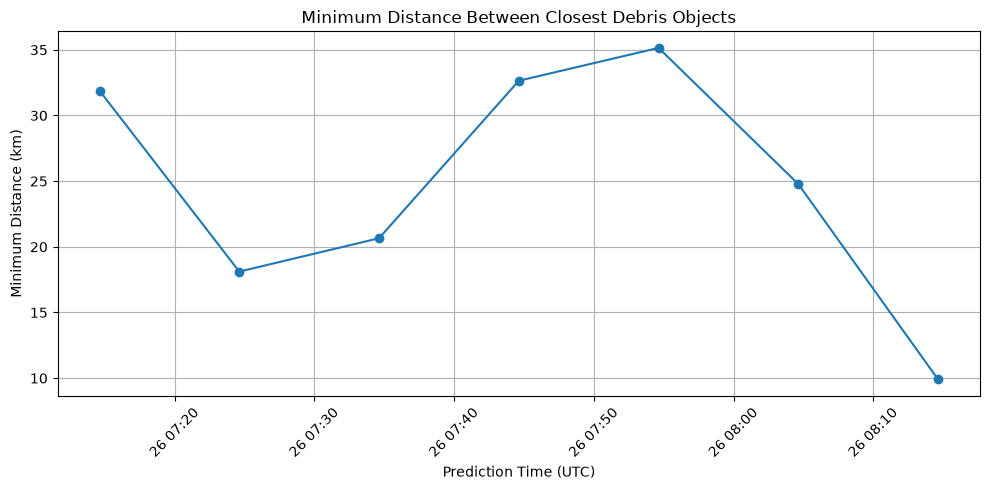

In [298]:
#Visualize the separation over time
plt.figure(figsize=(10, 5))

plt.plot(
    closest_approach_summary["prediction_time_utc"],
    closest_approach_summary["minimum_distance_km"],
    marker="o"
)

plt.title("Minimum Distance Between Closest Debris Objects")
plt.xlabel("Prediction Time (UTC)")
plt.ylabel("Minimum Distance (km)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [299]:
#Calculate Relative velocity
# Select velocity records for Object A
velocity_A = analysis_df[
    analysis_df["norad_cat_id"] == 33762
][[
    "prediction_time_utc",
    "vx_teme_km_s",
    "vy_teme_km_s",
    "vz_teme_km_s"
]]

# Select velocity records for Object B
velocity_B = analysis_df[
    analysis_df["norad_cat_id"] == 34045
][[
    "prediction_time_utc",
    "vx_teme_km_s",
    "vy_teme_km_s",
    "vz_teme_km_s"
]]

# Match both objects at the same timestamps
velocity_pair = velocity_A.merge(
    velocity_B,
    on="prediction_time_utc",
    suffixes=("_A", "_B")
)

print(velocity_pair.head())

               prediction_time_utc  vx_teme_km_s_A  vy_teme_km_s_A  \
0 2026-10-26 07:14:37.419912+00:00        1.387331        5.643100   
1 2026-10-26 07:24:37.419912+00:00        0.248743        7.410725   
2 2026-10-26 07:34:37.419912+00:00       -0.982849        6.399004   
3 2026-10-26 07:44:37.419912+00:00       -1.849968        2.972025   
4 2026-10-26 07:54:37.419912+00:00       -2.021349       -1.600257   

   vz_teme_km_s_A  vx_teme_km_s_B  vy_teme_km_s_B  vz_teme_km_s_B  
0       -4.653343        1.357810        5.650419       -4.649539  
1       -0.601543        0.210656        7.404863       -0.599871  
2        3.675432       -1.013483        6.387723        3.668375  
3        6.584415       -1.862632        2.966469        6.575090  
4        7.009879       -2.013358       -1.600621        7.009511  


In [300]:
#Calculate relative velocity
# Calculate relative velocity components (B - A)

velocity_pair["relative_vx"] = (
    velocity_pair["vx_teme_km_s_B"] -
    velocity_pair["vx_teme_km_s_A"]
)

velocity_pair["relative_vy"] = (
    velocity_pair["vy_teme_km_s_B"] -
    velocity_pair["vy_teme_km_s_A"]
)

velocity_pair["relative_vz"] = (
    velocity_pair["vz_teme_km_s_B"] -
    velocity_pair["vz_teme_km_s_A"]
)

# Calculate relative velocity magnitude

velocity_pair["relative_speed_km_s"] = np.sqrt(
    velocity_pair["relative_vx"]**2 +
    velocity_pair["relative_vy"]**2 +
    velocity_pair["relative_vz"]**2
)

print(
    velocity_pair[
        [
            "prediction_time_utc",
            "relative_vx",
            "relative_vy",
            "relative_vz",
            "relative_speed_km_s"
        ]
    ]
)

               prediction_time_utc  relative_vx  relative_vy  relative_vz  \
0 2026-10-26 07:14:37.419912+00:00    -0.029522     0.007319     0.003803   
1 2026-10-26 07:24:37.419912+00:00    -0.038087    -0.005862     0.001672   
2 2026-10-26 07:34:37.419912+00:00    -0.030634    -0.011282    -0.007057   
3 2026-10-26 07:44:37.419912+00:00    -0.012664    -0.005556    -0.009325   
4 2026-10-26 07:54:37.419912+00:00     0.007992    -0.000364    -0.000368   
5 2026-10-26 08:04:37.419912+00:00     0.025774    -0.004466     0.008191   
6 2026-10-26 08:14:37.419912+00:00     0.036534    -0.009704     0.003864   

   relative_speed_km_s  
0             0.030652  
1             0.038572  
2             0.033399  
3             0.016679  
4             0.008008  
5             0.027410  
6             0.037998  


In [301]:
#Calculate approach and recession rate 
# Object A positions
position_A_df = analysis_df[
    analysis_df["norad_cat_id"] == 33762
][[
    "prediction_time_utc",
    "x_teme_km",
    "y_teme_km",
    "z_teme_km"
]]

# Object B positions
position_B_df = analysis_df[
    analysis_df["norad_cat_id"] == 34045
][[
    "prediction_time_utc",
    "x_teme_km",
    "y_teme_km",
    "z_teme_km"
]]

# Match positions by timestamp
position_pair = position_A_df.merge(
    position_B_df,
    on="prediction_time_utc",
    suffixes=("_A", "_B")
)

print(position_pair.head())

               prediction_time_utc  x_teme_km_A  y_teme_km_A  z_teme_km_A  \
0 2026-10-26 07:14:37.419912+00:00  1453.504450 -4672.848357 -5244.104851   
1 2026-10-26 07:24:37.419912+00:00  1960.618026  -624.920553 -6872.979813   
2 2026-10-26 07:34:37.419912+00:00  1733.170776  3657.214271 -5920.386494   
3 2026-10-26 07:44:37.419912+00:00   854.946083  6564.517618 -2739.287013   
4 2026-10-26 07:54:37.419912+00:00  -345.832978  6991.199707  1477.706489   

   x_teme_km_B  y_teme_km_B  z_teme_km_B  
0  1479.908541 -4657.123605 -5252.608892  
1  1965.913869  -608.790732 -6879.288145  
2  1717.134033  3667.553431 -5928.288141  
3   825.601578  6569.454445 -2752.703035  
4  -376.544578  6994.735842  1460.992304  


In [302]:
#Calculate the rate of approach/recession
# Combine position and velocity data
approach_df = position_pair.merge(
    velocity_pair,
    on="prediction_time_utc"
)

# Calculate relative position components (B - A)
approach_df["relative_rx"] = (
    approach_df["x_teme_km_B"] - approach_df["x_teme_km_A"]
)

approach_df["relative_ry"] = (
    approach_df["y_teme_km_B"] - approach_df["y_teme_km_A"]
)

approach_df["relative_rz"] = (
    approach_df["z_teme_km_B"] - approach_df["z_teme_km_A"]
)

print(
    approach_df[
        [
            "prediction_time_utc",
            "relative_rx",
            "relative_ry",
            "relative_rz",
            "relative_vx",
            "relative_vy",
            "relative_vz"
        ]
    ]
)

               prediction_time_utc  relative_rx  relative_ry  relative_rz  \
0 2026-10-26 07:14:37.419912+00:00    26.404091    15.724752    -8.504042   
1 2026-10-26 07:24:37.419912+00:00     5.295843    16.129820    -6.308333   
2 2026-10-26 07:34:37.419912+00:00   -16.036743    10.339160    -7.901647   
3 2026-10-26 07:44:37.419912+00:00   -29.344505     4.936828   -13.416023   
4 2026-10-26 07:54:37.419912+00:00   -30.711600     3.536135   -16.714186   
5 2026-10-26 08:04:37.419912+00:00   -20.336652     2.500541   -13.931357   
6 2026-10-26 08:14:37.419912+00:00    -1.177312    -2.099101    -9.603510   

   relative_vx  relative_vy  relative_vz  
0    -0.029522     0.007319     0.003803  
1    -0.038087    -0.005862     0.001672  
2    -0.030634    -0.011282    -0.007057  
3    -0.012664    -0.005556    -0.009325  
4     0.007992    -0.000364    -0.000368  
5     0.025774    -0.004466     0.008191  
6     0.036534    -0.009704     0.003864  


In [303]:
#Calculate the rate of approach/recession
# Calculate separation distance
approach_df["separation_km"] = np.sqrt(
    approach_df["relative_rx"]**2 +
    approach_df["relative_ry"]**2 +
    approach_df["relative_rz"]**2
)

# Calculate dot product of relative position and velocity
approach_df["position_velocity_dot"] = (
    approach_df["relative_rx"] * approach_df["relative_vx"] +
    approach_df["relative_ry"] * approach_df["relative_vy"] +
    approach_df["relative_rz"] * approach_df["relative_vz"]
)

# Calculate rate of approach/recession
approach_df["separation_rate_km_s"] = (
    approach_df["position_velocity_dot"] /
    approach_df["separation_km"]
)

print(
    approach_df[
        [
            "prediction_time_utc",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s"
        ]
    ]
)

               prediction_time_utc  separation_km  relative_speed_km_s  \
0 2026-10-26 07:14:37.419912+00:00      31.886714             0.030652   
1 2026-10-26 07:24:37.419912+00:00      18.111105             0.038572   
2 2026-10-26 07:34:37.419912+00:00      20.652152             0.033399   
3 2026-10-26 07:44:37.419912+00:00      32.641414             0.016679   
4 2026-10-26 07:54:37.419912+00:00      35.143572             0.008008   
5 2026-10-26 08:04:37.419912+00:00      24.777305             0.027410   
6 2026-10-26 08:14:37.419912+00:00       9.900489             0.037998   

   separation_rate_km_s  
0             -0.021851  
1             -0.016940  
2              0.020840  
3              0.014377  
4             -0.006845  
5             -0.026211  
6             -0.006035  


In [304]:
#Classify approach and recession
def classify_motion(rate):
    if rate < 0:
        return "APPROACHING"
    elif rate > 0:
        return "RECEDING"
    else:
        return "INSTANTANEOUSLY STATIONARY"


approach_df["motion_status"] = (
    approach_df["separation_rate_km_s"]
    .apply(classify_motion)
)

print(
    approach_df[
        [
            "prediction_time_utc",
            "separation_km",
            "separation_rate_km_s",
            "motion_status"
        ]
    ]
)

               prediction_time_utc  separation_km  separation_rate_km_s  \
0 2026-10-26 07:14:37.419912+00:00      31.886714             -0.021851   
1 2026-10-26 07:24:37.419912+00:00      18.111105             -0.016940   
2 2026-10-26 07:34:37.419912+00:00      20.652152              0.020840   
3 2026-10-26 07:44:37.419912+00:00      32.641414              0.014377   
4 2026-10-26 07:54:37.419912+00:00      35.143572             -0.006845   
5 2026-10-26 08:04:37.419912+00:00      24.777305             -0.026211   
6 2026-10-26 08:14:37.419912+00:00       9.900489             -0.006035   

  motion_status  
0   APPROACHING  
1   APPROACHING  
2      RECEDING  
3      RECEDING  
4   APPROACHING  
5   APPROACHING  
6   APPROACHING  


In [305]:
#Identify the closest sampled approach
closest_row = approach_df.loc[
    approach_df["separation_km"].idxmin()
]

print("Closest Sampled Approach")
print("------------------------")
print("Time:", closest_row["prediction_time_utc"])
print("Separation:", closest_row["separation_km"], "km")
print("Relative Speed:", closest_row["relative_speed_km_s"], "km/s")
print("Separation Rate:", closest_row["separation_rate_km_s"], "km/s")
print("Motion Status:", closest_row["motion_status"])

Closest Sampled Approach
------------------------
Time: 2026-10-26 08:14:37.419912+00:00
Separation: 9.900489328772451 km
Relative Speed: 0.037997636712085246 km/s
Separation Rate: -0.006034699431941016 km/s
Motion Status: APPROACHING


In [306]:
#Prepare a clean report for this containg all seven observation.
close_approach_report = approach_df[
    [
        "prediction_time_utc",
        "separation_km",
        "relative_speed_km_s",
        "separation_rate_km_s",
        "motion_status"
    ]
].copy()

close_approach_report



,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status
0,2026-10-26 07:14:37.419912+00:00,31.886714,0.030652,-0.021851,APPROACHING
1,2026-10-26 07:24:37.419912+00:00,18.111105,0.038572,-0.016940,APPROACHING
2,2026-10-26 07:34:37.419912+00:00,20.652152,0.033399,0.020840,RECEDING
3,2026-10-26 07:44:37.419912+00:00,32.641414,0.016679,0.014377,RECEDING
4,2026-10-26 07:54:37.419912+00:00,35.143572,0.008008,-0.006845,APPROACHING
5,2026-10-26 08:04:37.419912+00:00,24.777305,0.027410,-0.026211,APPROACHING
6,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING


In [307]:
#Identify close-approach candidates among all 580 objects.
#Calculate distances for all pairs at the first timestamps.
from scipy.spatial.distance import pdist

first_timestamp = analysis_df["prediction_time_utc"].min()

timestamp_df = analysis_df[
    analysis_df["prediction_time_utc"] == first_timestamp
].copy()

positions = timestamp_df[
    ["x_teme_km", "y_teme_km", "z_teme_km"]
].to_numpy()

all_distances = pdist(positions, metric="euclidean")

print("Timestamp:", first_timestamp)
print("Total objects:", len(timestamp_df))
print("Total unique pairs:", len(all_distances))
print("Minimum distance:", all_distances.min(), "km")
print("Maximum distance:", all_distances.max(), "km")

Timestamp: 2026-10-26 07:14:37.419912+00:00
Total objects: 580
Total unique pairs: 167910
Minimum distance: 31.88671445729405 km
Maximum distance: 15409.033010053778 km


In [308]:
#Extract pairs within a screening distance.
import numpy as np

screening_threshold_km = 100

pair_indices = np.triu_indices(len(timestamp_df), k=1)

close_mask = all_distances < screening_threshold_km

close_pairs = pd.DataFrame({
    "object_A_id": timestamp_df.iloc[pair_indices[0]]["norad_cat_id"].to_numpy()[close_mask],
    "object_B_id": timestamp_df.iloc[pair_indices[1]]["norad_cat_id"].to_numpy()[close_mask],
    "object_A_name": timestamp_df.iloc[pair_indices[0]]["object_name"].to_numpy()[close_mask],
    "object_B_name": timestamp_df.iloc[pair_indices[1]]["object_name"].to_numpy()[close_mask],
    "separation_km": all_distances[close_mask]
})

close_pairs = close_pairs.sort_values(
    by="separation_km"
).reset_index(drop=True)

print("Screening threshold:", screening_threshold_km, "km")
print("Total candidate pairs:", len(close_pairs))

close_pairs.head(10)

Screening threshold: 100 km
Total candidate pairs: 6


,object_A_id,object_B_id,object_A_name,object_B_name,separation_km
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,31.886714
1,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,57.188135
2,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB,64.665809
3,34387,34796,COSMOS 2251 DEB,COSMOS 2251 DEB,72.304247
4,35645,37108,COSMOS 2251 DEB,COSMOS 2251 DEB,73.396262
5,34609,36385,COSMOS 2251 DEB,COSMOS 2251 DEB,85.810514


In [309]:
#screen all seven timestamps
candidate_tables = []

all_timestamps = sorted(
    analysis_df["prediction_time_utc"].unique()
)

for timestamp in all_timestamps:

    current_df = analysis_df[
        analysis_df["prediction_time_utc"] == timestamp
    ].copy()

    positions = current_df[
        ["x_teme_km", "y_teme_km", "z_teme_km"]
    ].to_numpy()

    distances = pdist(positions, metric="euclidean")

    pair_indices = np.triu_indices(len(current_df), k=1)

    close_mask = distances < screening_threshold_km

    candidates = pd.DataFrame({
        "prediction_time_utc": timestamp,
        "object_A_id": current_df.iloc[pair_indices[0]]["norad_cat_id"].to_numpy()[close_mask],
        "object_B_id": current_df.iloc[pair_indices[1]]["norad_cat_id"].to_numpy()[close_mask],
        "object_A_name": current_df.iloc[pair_indices[0]]["object_name"].to_numpy()[close_mask],
        "object_B_name": current_df.iloc[pair_indices[1]]["object_name"].to_numpy()[close_mask],
        "separation_km": distances[close_mask]
    })

    candidate_tables.append(candidates)

all_close_approaches = pd.concat(
    candidate_tables,
    ignore_index=True
)

print("Total candidate observations:", len(all_close_approaches))

print("\nCandidates at each timestamp:")
print(
    all_close_approaches.groupby("prediction_time_utc").size()
)

print("\nFirst 15 candidate observations:")
display(all_close_approaches.head(15))

Total candidate observations: 58

Candidates at each timestamp:
prediction_time_utc
2026-10-26 07:14:37.419912+00:00     6
2026-10-26 07:24:37.419912+00:00    12
2026-10-26 07:34:37.419912+00:00    10
2026-10-26 07:44:37.419912+00:00     5
2026-10-26 07:54:37.419912+00:00    10
2026-10-26 08:04:37.419912+00:00     7
2026-10-26 08:14:37.419912+00:00     8
dtype: int64

First 15 candidate observations:


,prediction_time_utc,object_A_id,object_B_id,object_A_name,object_B_name,separation_km
0,2026-10-26 07:14:37.419912+00:00,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,31.886714
1,2026-10-26 07:14:37.419912+00:00,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB,64.665809
2,2026-10-26 07:14:37.419912+00:00,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,57.188135
3,2026-10-26 07:14:37.419912+00:00,34387,34796,COSMOS 2251 DEB,COSMOS 2251 DEB,72.304247
4,2026-10-26 07:14:37.419912+00:00,34609,36385,COSMOS 2251 DEB,COSMOS 2251 DEB,85.810514
5,2026-10-26 07:14:37.419912+00:00,35645,37108,COSMOS 2251 DEB,COSMOS 2251 DEB,73.396262
6,2026-10-26 07:24:37.419912+00:00,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,18.111105
7,2026-10-26 07:24:37.419912+00:00,33942,35434,COSMOS 2251 DEB,COSMOS 2251 DEB,90.251185
8,2026-10-26 07:24:37.419912+00:00,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB,53.317974
9,2026-10-26 07:24:37.419912+00:00,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,46.156564


In [310]:
#Identify unique candidate pairs
unique_pairs = (
    all_close_approaches[
        ["object_A_id", "object_B_id",
         "object_A_name", "object_B_name"]
    ]
    .drop_duplicates(
        subset=["object_A_id", "object_B_id"]
    )
    .reset_index(drop=True)
)

print("Total candidate observations:", len(all_close_approaches))
print("Total unique candidate pairs:", len(unique_pairs))

display(unique_pairs)

Total candidate observations: 58
Total unique candidate pairs: 32


,object_A_id,object_B_id,object_A_name,object_B_name
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB
1,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB
2,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB
3,34387,34796,COSMOS 2251 DEB,COSMOS 2251 DEB
4,34609,36385,COSMOS 2251 DEB,COSMOS 2251 DEB
5,35645,37108,COSMOS 2251 DEB,COSMOS 2251 DEB
6,33942,35434,COSMOS 2251 DEB,COSMOS 2251 DEB
7,34303,37293,COSMOS 2251 DEB,COSMOS 2251 DEB
8,34635,34953,COSMOS 2251 DEB,COSMOS 2251 DEB
9,34729,37326,COSMOS 2251 DEB,COSMOS 2251 DEB


In [311]:
#calculate minimum separation for every pair
pair_summary = (
    all_close_approaches
    .groupby(
        ["object_A_id", "object_B_id",
         "object_A_name", "object_B_name"]
    )
    .agg(
        minimum_separation_km=("separation_km", "min"),
        maximum_separation_km=("separation_km", "max"),
        observation_count=("separation_km", "count")
    )
    .reset_index()
)

pair_summary = pair_summary.sort_values(
    by="minimum_separation_km"
).reset_index(drop=True)

print("Total unique candidate pairs:", len(pair_summary))

display(pair_summary)

Total unique candidate pairs: 32


,object_A_id,object_B_id,object_A_name,object_B_name,minimum_separation_km,maximum_separation_km,observation_count
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,9.900489,35.143572,7
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,33.149825,33.149825,1
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,33.199266,33.199266,1
3,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,40.636882,84.225931,7
4,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,49.847261,79.985302,4
5,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB,53.317974,90.292265,3
6,34635,34953,COSMOS 2251 DEB,COSMOS 2251 DEB,58.146888,58.146888,1
7,35614,35885,COSMOS 2251 DEB,COSMOS 2251 DEB,58.502498,75.596344,3
8,34944,35060,COSMOS 2251 DEB,COSMOS 2251 DEB,58.511774,58.511774,1
9,33797,38055,COSMOS 2251 DEB,COSMOS 2251 DEB,60.986675,60.986675,1


In [312]:
#find the exact timestamps of minimum separation for each pair.
pair_minimum_events = (
    all_close_approaches
    .loc[
        all_close_approaches.groupby(
            ["object_A_id", "object_B_id"]
        )["separation_km"].idxmin()
    ]
    .sort_values("separation_km")
    .reset_index(drop=True)
)

pair_minimum_events = pair_minimum_events.merge(
    pair_summary[
        ["object_A_id", "object_B_id", "observation_count"]
    ],
    on=["object_A_id", "object_B_id"],
    how="left"
)

print("Total pairs:", len(pair_minimum_events))

display(
    pair_minimum_events[
        [
            "object_A_id",
            "object_B_id",
            "prediction_time_utc",
            "separation_km",
            "observation_count"
        ]
    ]
)

Total pairs: 32


,object_A_id,object_B_id,prediction_time_utc,separation_km,observation_count
0,33762,34045,2026-10-26 08:14:37.419912+00:00,9.900489,7
1,34571,34635,2026-10-26 07:34:37.419912+00:00,33.149825,1
2,33766,37483,2026-10-26 07:34:37.419912+00:00,33.199266,1
3,34297,36632,2026-10-26 07:34:37.419912+00:00,40.636882,7
4,33994,47068,2026-10-26 08:04:37.419912+00:00,49.847261,4
5,34273,34547,2026-10-26 07:24:37.419912+00:00,53.317974,3
6,34635,34953,2026-10-26 07:24:37.419912+00:00,58.146888,1
7,35614,35885,2026-10-26 08:04:37.419912+00:00,58.502498,3
8,34944,35060,2026-10-26 07:44:37.419912+00:00,58.511774,1
9,33797,38055,2026-10-26 08:04:37.419912+00:00,60.986675,1


In [313]:
#Calculate relative velocity for all 32 pairs
# Select position and velocity information for each object
state_columns = [
    "prediction_time_utc",
    "norad_cat_id",
    "x_teme_km", "y_teme_km", "z_teme_km",
    "vx_teme_km_s", "vy_teme_km_s", "vz_teme_km_s"
]

# Prepare the state information for Object A
states_A = analysis_df[state_columns].rename(columns={
    "norad_cat_id": "object_A_id",
    "x_teme_km": "x_A",
    "y_teme_km": "y_A",
    "z_teme_km": "z_A",
    "vx_teme_km_s": "vx_A",
    "vy_teme_km_s": "vy_A",
    "vz_teme_km_s": "vz_A"
})

# Prepare the state information for Object B
states_B = analysis_df[state_columns].rename(columns={
    "norad_cat_id": "object_B_id",
    "x_teme_km": "x_B",
    "y_teme_km": "y_B",
    "z_teme_km": "z_B",
    "vx_teme_km_s": "vx_B",
    "vy_teme_km_s": "vy_B",
    "vz_teme_km_s": "vz_B"
})

# Match each candidate pair with both objects' states
candidate_motion = pair_minimum_events.merge(
    states_A,
    on=["prediction_time_utc", "object_A_id"],
    how="left"
)

candidate_motion = candidate_motion.merge(
    states_B,
    on=["prediction_time_utc", "object_B_id"],
    how="left"
)

print("Total candidate pairs:", len(candidate_motion))
display(candidate_motion.head())


Total candidate pairs: 32


,prediction_time_utc,object_A_id,object_B_id,object_A_name,object_B_name,separation_km,observation_count,x_A,y_A,z_A,vx_A,vy_A,vz_A,x_B,y_B,z_B,vx_B,vy_B,vz_B
0,2026-10-26 08:14:37.419912+00:00,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,9.900489,7,-1946.695936,727.618430,6830.789020,-0.288207,-7.435876,0.709861,-1947.873248,725.519329,6821.185510,-0.251673,-7.445580,0.713725
1,2026-10-26 07:34:37.419912+00:00,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,33.149825,1,-3405.596358,1994.295466,-5848.830190,2.827884,-5.949016,-3.652723,-3380.886358,1981.977267,-5867.176545,-6.560199,-0.458736,3.607843
2,2026-10-26 07:34:37.419912+00:00,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,33.199266,1,-2013.463446,312.387199,-6887.134999,0.856217,-7.357995,-0.544545,-1984.022919,327.487283,-6889.861554,-0.009263,-7.412207,-0.301211
3,2026-10-26 07:34:37.419912+00:00,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,40.636882,7,524.851768,-2902.734997,-6529.810620,3.994045,5.854576,-2.278101,536.433875,-2863.785099,-6530.151865,4.032611,5.844223,-2.242854
4,2026-10-26 08:04:37.419912+00:00,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,49.847261,4,-5644.080729,4384.796577,190.184798,-1.419042,-1.494113,-7.170423,-5601.398564,4361.126184,180.050958,-1.410054,-1.513220,-7.196631


In [314]:
#Calculate relative velocity for  all 32 pairs
# Calculate relative velocity components
candidate_motion["relative_vx"] = (
    candidate_motion["vx_B"] - candidate_motion["vx_A"]
)

candidate_motion["relative_vy"] = (
    candidate_motion["vy_B"] - candidate_motion["vy_A"]
)

candidate_motion["relative_vz"] = (
    candidate_motion["vz_B"] - candidate_motion["vz_A"]
)

# Calculate relative speed
candidate_motion["relative_speed_km_s"] = np.sqrt(
    candidate_motion["relative_vx"]**2 +
    candidate_motion["relative_vy"]**2 +
    candidate_motion["relative_vz"]**2
)

# Display results
display(
    candidate_motion[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_vx",
            "relative_vy",
            "relative_vz",
            "relative_speed_km_s"
        ]
    ].head(10)
)

,object_A_id,object_B_id,separation_km,relative_vx,relative_vy,relative_vz,relative_speed_km_s
0,33762,34045,9.900489,0.036534,-0.009704,0.003864,0.037998
1,34571,34635,33.149825,-9.388082,5.490280,7.260566,13.076509
2,33766,37483,33.199266,-0.865480,-0.054212,0.243333,0.900670
3,34297,36632,40.636882,0.038567,-0.010353,0.035247,0.053263
4,33994,47068,49.847261,0.008988,-0.019108,-0.026208,0.033657
5,34273,34547,53.317974,0.006386,0.061406,-0.007241,0.062160
6,34635,34953,58.146888,2.149744,4.387826,1.607801,5.143874
7,35614,35885,58.502498,-0.029050,0.000184,0.000878,0.029064
8,34944,35060,58.511774,-0.155722,0.372798,0.059909,0.408432
9,33797,38055,60.986675,-6.727615,6.509627,10.495677,14.063971


In [315]:
#Calculate the separation rate
# Calculate relative position components
candidate_motion["relative_rx"] = (
    candidate_motion["x_B"] - candidate_motion["x_A"]
)

candidate_motion["relative_ry"] = (
    candidate_motion["y_B"] - candidate_motion["y_A"]
)

candidate_motion["relative_rz"] = (
    candidate_motion["z_B"] - candidate_motion["z_A"]
)

# Calculate dot product of relative position and velocity
candidate_motion["position_velocity_dot"] = (
    candidate_motion["relative_rx"] * candidate_motion["relative_vx"] +
    candidate_motion["relative_ry"] * candidate_motion["relative_vy"] +
    candidate_motion["relative_rz"] * candidate_motion["relative_vz"]
)

# Calculate separation rate
candidate_motion["separation_rate_km_s"] = (
    candidate_motion["position_velocity_dot"] /
    candidate_motion["separation_km"]
)

# Display results
display(
    candidate_motion[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s"
        ]
    ].head(10)
)

,object_A_id,object_B_id,separation_km,relative_speed_km_s,separation_rate_km_s
0,33762,34045,9.900489,0.037998,-0.006035
1,34571,34635,33.149825,13.076509,-13.056323
2,33766,37483,33.199266,0.900670,-0.812134
3,34297,36632,40.636882,0.053263,0.000772
4,33994,47068,49.847261,0.033657,0.022098
5,34273,34547,53.317974,0.062160,0.030702
6,34635,34953,58.146888,5.143874,-2.650539
7,35614,35885,58.502498,0.029064,-0.019881
8,34944,35060,58.511774,0.408432,-0.054839
9,33797,38055,60.986675,14.063971,3.837172


In [316]:
#Classify all 32 pairs
def classify_motion(rate):

    if rate < 0:
        return "APPROACHING"

    elif rate > 0:
        return "RECEDING"

    else:
        return "INSTANTANEOUSLY_STATIONARY"


candidate_motion["motion_status"] = (
    candidate_motion["separation_rate_km_s"]
    .apply(classify_motion)
)

print(candidate_motion["motion_status"].value_counts())

display(
    candidate_motion[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s",
            "motion_status"
        ]
    ]
)

motion_status
RECEDING       20
APPROACHING    12
Name: count, dtype: int64


,object_A_id,object_B_id,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status
0,33762,34045,9.900489,0.037998,-0.006035,APPROACHING
1,34571,34635,33.149825,13.076509,-13.056323,APPROACHING
2,33766,37483,33.199266,0.900670,-0.812134,APPROACHING
3,34297,36632,40.636882,0.053263,0.000772,RECEDING
4,33994,47068,49.847261,0.033657,0.022098,RECEDING
5,34273,34547,53.317974,0.062160,0.030702,RECEDING
6,34635,34953,58.146888,5.143874,-2.650539,APPROACHING
7,35614,35885,58.502498,0.029064,-0.019881,APPROACHING
8,34944,35060,58.511774,0.408432,-0.054839,APPROACHING
9,33797,38055,60.986675,14.063971,3.837172,RECEDING


In [317]:
#Create the combined close-approach report 
close_approach_report = candidate_motion[
    [
        "object_A_id",
        "object_B_id",
        "object_A_name",
        "object_B_name",
        "prediction_time_utc",
        "separation_km",
        "relative_speed_km_s",
        "separation_rate_km_s",
        "motion_status",
        "observation_count"
    ]
].copy()

# Sort by smallest separation
close_approach_report = close_approach_report.sort_values(
    by="separation_km"
).reset_index(drop=True)

print("Total close-approach candidates:", len(close_approach_report))

display(close_approach_report)

Total close-approach candidates: 32


,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING,7
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.199266,0.900670,-0.812134,APPROACHING,1
3,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,40.636882,0.053263,0.000772,RECEDING,7
4,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,49.847261,0.033657,0.022098,RECEDING,4
5,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:24:37.419912+00:00,53.317974,0.062160,0.030702,RECEDING,3
6,34635,34953,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:24:37.419912+00:00,58.146888,5.143874,-2.650539,APPROACHING,1
7,35614,35885,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,58.502498,0.029064,-0.019881,APPROACHING,3
8,34944,35060,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:44:37.419912+00:00,58.511774,0.408432,-0.054839,APPROACHING,1
9,33797,38055,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,60.986675,14.063971,3.837172,RECEDING,1


In [318]:
#Save the report 
close_approach_report.to_csv(
    "close_approach_report.csv",
    index=False
)

print("Close approach report saved successfully!")


Close approach report saved successfully!


In [319]:
saved_close_approach = pd.read_csv("close_approach_report.csv")

print("Rows:", saved_close_approach.shape[0])
print("Columns:", saved_close_approach.shape[1])

display(saved_close_approach.head())

Rows: 32
Columns: 10


,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING,7
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.199266,0.900670,-0.812134,APPROACHING,1
3,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,40.636882,0.053263,0.000772,RECEDING,7
4,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,49.847261,0.033657,0.022098,RECEDING,4


In [320]:
#Statistical Summary
# Basic statistical summary

print("SEPARATION DISTANCE (KM)")
display(close_approach_report["separation_km"].describe())

print("RELATIVE SPEED (KM/S)")
display(close_approach_report["relative_speed_km_s"].describe())

print("SEPARATION RATE (KM/S)")
display(close_approach_report["separation_rate_km_s"].describe())


SEPARATION DISTANCE (KM)


count    32.000000
mean     68.129228
std      19.228630
min       9.900489
25%      58.509455
50%      70.371890
75%      80.835975
max      95.507892
Name: separation_km, dtype: float64

RELATIVE SPEED (KM/S)


count    32.000000
mean      3.553513
std       5.248241
min       0.029064
25%       0.075390
50%       0.728736
75%       4.341507
max      14.530746
Name: relative_speed_km_s, dtype: float64

SEPARATION RATE (KM/S)


count    32.000000
mean      0.440836
std       4.060308
min     -13.056323
25%      -0.050495
50%       0.026400
75%       0.966641
max      12.928335
Name: separation_rate_km_s, dtype: float64

In [321]:
#Count approaching and receding pairs
motion_counts = close_approach_report["motion_status"].value_counts()

print("Motion Status Summary:")
display(motion_counts)

Motion Status Summary:


motion_status
RECEDING       20
APPROACHING    12
Name: count, dtype: int64

In [322]:
#Verify motion classifications
# Compare motion labels with separation-rate signs

display(
    close_approach_report.groupby("motion_status")[
        "separation_rate_km_s"
    ].agg(["count", "min", "max"])
)

,count,min,max
motion_status,,,
APPROACHING,12,-13.056323,-0.006035
RECEDING,20,0.000772,12.928335


In [323]:
#Find the 5 closest candidate pairs
top_5_closest = close_approach_report.nsmallest(
    5, "separation_km"
)

display(top_5_closest)

,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING,7
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.199266,0.900670,-0.812134,APPROACHING,1
3,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,40.636882,0.053263,0.000772,RECEDING,7
4,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,49.847261,0.033657,0.022098,RECEDING,4


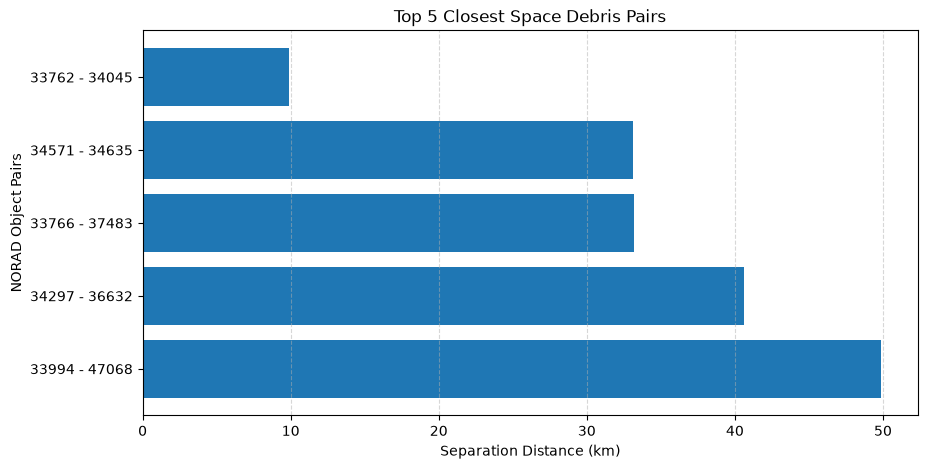

In [324]:
#Visualize the five closest pairs
plt.figure(figsize=(10, 5))

pair_labels = (
    top_5_closest["object_A_id"].astype(str)
    + " - "
    + top_5_closest["object_B_id"].astype(str)
)

plt.barh(pair_labels, top_5_closest["separation_km"])

plt.xlabel("Separation Distance (km)")
plt.ylabel("NORAD Object Pairs")
plt.title("Top 5 Closest Space Debris Pairs")

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()

In [325]:
#Find the 5 pairs with the highest relative speed.
top_5_fastest = close_approach_report.nlargest(
    5, "relative_speed_km_s"
)

display(top_5_fastest)

,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
10,35759,35786,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:24:37.419912+00:00,65.926493,14.530746,5.738404,RECEDING,1
31,35456,38067,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,95.507892,14.384705,12.928335,RECEDING,1
30,35015,39110,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:24:37.419912+00:00,93.158093,14.344542,4.339527,RECEDING,1
9,33797,38055,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,60.986675,14.063971,3.837172,RECEDING,1
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1


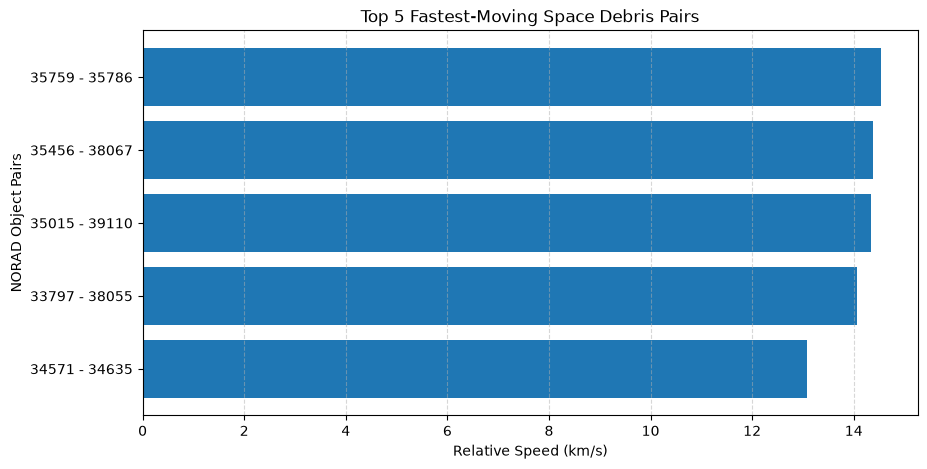

In [326]:
#Visualize the five fastest pairs
plt.figure(figsize=(10, 5))

pair_labels = (
    top_5_fastest["object_A_id"].astype(str)
    + " - "
    + top_5_fastest["object_B_id"].astype(str)
)

plt.barh(
    pair_labels,
    top_5_fastest["relative_speed_km_s"]
)

plt.xlabel("Relative Speed (km/s)")
plt.ylabel("NORAD Object Pairs")
plt.title("Top 5 Fastest-Moving Space Debris Pairs")

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()


In [327]:
#Identify higher-relative-speeed pairs
# Identify pairs above the 75th percentile of relative speed

speed_threshold = close_approach_report[
    "relative_speed_km_s"
].quantile(0.75)

high_speed_pairs = close_approach_report[
    close_approach_report["relative_speed_km_s"] > speed_threshold
].copy()

print("Relative speed threshold:", speed_threshold, "km/s")
print("Number of higher-speed pairs:", len(high_speed_pairs))

display(
    high_speed_pairs[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s",
            "motion_status"
        ]
    ]
)

Relative speed threshold: 4.34150726662137 km/s
Number of higher-speed pairs: 8


,object_A_id,object_B_id,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status
1,34571,34635,33.149825,13.076509,-13.056323,APPROACHING
6,34635,34953,58.146888,5.143874,-2.650539,APPROACHING
9,33797,38055,60.986675,14.063971,3.837172,RECEDING
10,35759,35786,65.926493,14.530746,5.738404,RECEDING
21,33932,34563,80.013270,12.392360,-7.377782,APPROACHING
29,33942,35434,90.251185,6.029308,5.688703,RECEDING
30,35015,39110,93.158093,14.344542,4.339527,RECEDING
31,35456,38067,95.507892,14.384705,12.928335,RECEDING


In [328]:
#Count motion status among higher-speed pairs
high_speed_motion = high_speed_pairs["motion_status"].value_counts()

print("Motion status of higher-speed pairs:")
display(high_speed_motion)

Motion status of higher-speed pairs:


motion_status
RECEDING       5
APPROACHING    3
Name: count, dtype: int64

In [329]:
#Identify higher-speed pairs that are approaching
high_speed_approaching = high_speed_pairs[
    high_speed_pairs["motion_status"] == "APPROACHING"
].copy()

high_speed_approaching = high_speed_approaching.sort_values(
    by="separation_km"
)

display(
    high_speed_approaching[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s",
            "motion_status"
        ]
    ]
)

,object_A_id,object_B_id,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status
1,34571,34635,33.149825,13.076509,-13.056323,APPROACHING
6,34635,34953,58.146888,5.143874,-2.650539,APPROACHING
21,33932,34563,80.013270,12.392360,-7.377782,APPROACHING


In [330]:
#Prepare a priority- review table 
priority_review = high_speed_approaching[
    [
        "object_A_id",
        "object_B_id",
        "prediction_time_utc",
        "separation_km",
        "relative_speed_km_s",
        "separation_rate_km_s",
        "motion_status",
        "observation_count"
    ]
].copy()

display(priority_review)

,object_A_id,object_B_id,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
1,34571,34635,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1
6,34635,34953,2026-10-26 07:24:37.419912+00:00,58.146888,5.143874,-2.650539,APPROACHING,1
21,33932,34563,2026-10-26 07:54:37.419912+00:00,80.013270,12.392360,-7.377782,APPROACHING,1


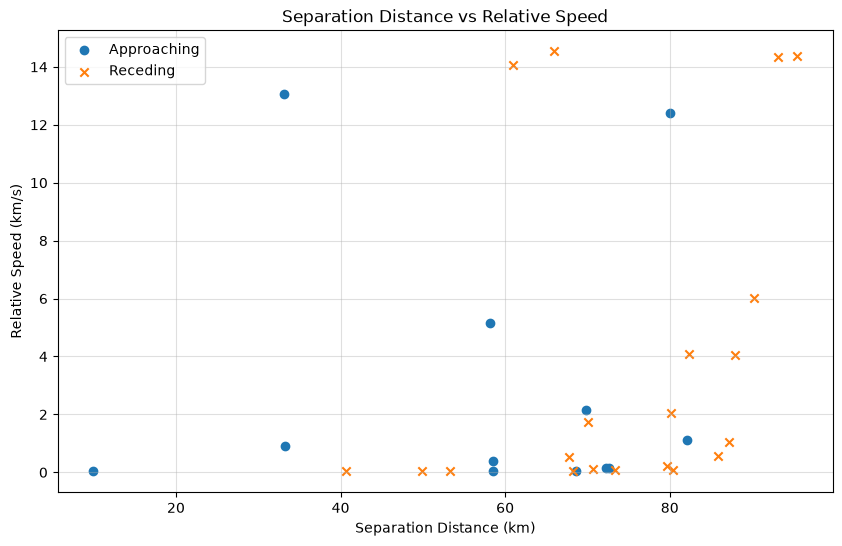

In [331]:
#Compare separation and relative speed
plt.figure(figsize=(10, 6))

approaching = close_approach_report[
    close_approach_report["motion_status"] == "APPROACHING"
]

receding = close_approach_report[
    close_approach_report["motion_status"] == "RECEDING"
]

plt.scatter(
    approaching["separation_km"],
    approaching["relative_speed_km_s"],
    label="Approaching",
    marker="o"
)

plt.scatter(
    receding["separation_km"],
    receding["relative_speed_km_s"],
    label="Receding",
    marker="x"
)

plt.xlabel("Separation Distance (km)")
plt.ylabel("Relative Speed (km/s)")
plt.title("Separation Distance vs Relative Speed")

plt.legend()
plt.grid(alpha=0.4)

plt.show()

In [332]:
#Calculate correlation
# Calculate correlation

pearson_corr = close_approach_report[
    ["separation_km", "relative_speed_km_s"]
].corr(method="pearson")

spearman_corr = close_approach_report[
    ["separation_km", "relative_speed_km_s"]
].corr(method="spearman")

print("Pearson Correlation:")
display(pearson_corr)

print("Spearman Correlation:")
display(spearman_corr)

Pearson Correlation:


,separation_km,relative_speed_km_s
separation_km,1.000000,0.182927
relative_speed_km_s,0.182927,1.000000


Spearman Correlation:


,separation_km,relative_speed_km_s
separation_km,1.000000,0.398827
relative_speed_km_s,0.398827,1.000000


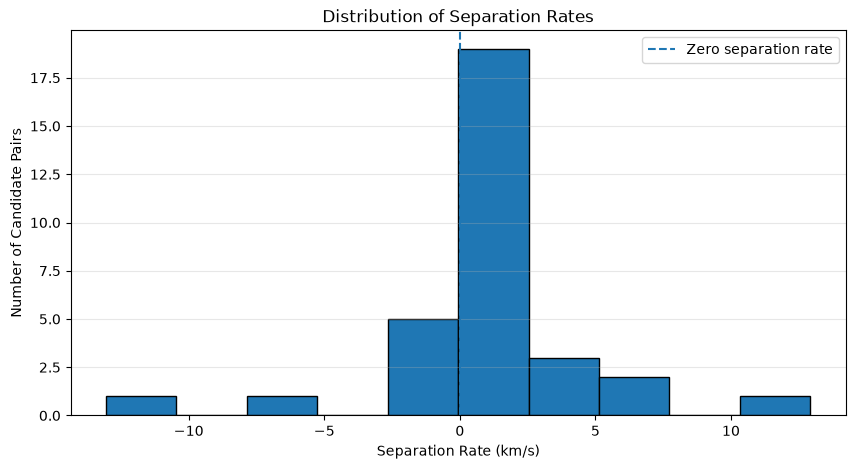

In [333]:
# Analyse separation rate
plt.figure(figsize=(10, 5))

plt.hist(
    close_approach_report["separation_rate_km_s"],
    bins=10,
    edgecolor="black"
)

plt.axvline(0, linestyle="--", label="Zero separation rate")

plt.xlabel("Separation Rate (km/s)")
plt.ylabel("Number of Candidate Pairs")
plt.title("Distribution of Separation Rates")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


In [334]:
#Find the fastest approaching and receding pairs
# Fastest approaching pair
fastest_approaching = close_approach_report.nsmallest(
    1, "separation_rate_km_s"
)

# Fastest receding pair
fastest_receding = close_approach_report.nlargest(
    1, "separation_rate_km_s"
)

print("Fastest Approaching Pair:")
display(fastest_approaching)

print("Fastest Receding Pair:")
display(fastest_receding)

Fastest Approaching Pair:


,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1


Fastest Receding Pair:


,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count
31,35456,38067,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,95.507892,14.384705,12.928335,RECEDING,1


In [335]:
#Summary of motion status
motion_summary = (
    close_approach_report
    .groupby("motion_status")
    .agg(
        pair_count=("object_A_id", "count"),
        average_separation_km=("separation_km", "mean"),
        average_relative_speed_km_s=("relative_speed_km_s", "mean"),
        average_separation_rate_km_s=("separation_rate_km_s", "mean")
    )
    .reset_index()
)

display(motion_summary)

,motion_status,pair_count,average_separation_km,average_relative_speed_km_s,average_separation_rate_km_s
0,APPROACHING,12,58.073126,2.969662,-2.211833
1,RECEDING,20,74.162889,3.903823,2.032438


In [336]:
#Save the Statistical summary
motion_summary.to_csv(
    "motion_status_summary.csv",
    index=False
)

print("Motion summary saved successfully!")

Motion summary saved successfully!


In [337]:
saved_motion_summary = pd.read_csv("motion_status_summary.csv")

print("Rows:", saved_motion_summary.shape[0])
print("Columns:", saved_motion_summary.shape[1])

display(saved_motion_summary)

Rows: 2
Columns: 5


,motion_status,pair_count,average_separation_km,average_relative_speed_km_s,average_separation_rate_km_s
0,APPROACHING,12,58.073126,2.969662,-2.211833
1,RECEDING,20,74.162889,3.903823,2.032438


In [338]:
#Analyse candidate counts by timestamp
timestamp_summary = (
    all_close_approaches
    .groupby("prediction_time_utc")
    .agg(
        candidate_count=("separation_km", "count"),
        minimum_separation_km=("separation_km", "min"),
        average_separation_km=("separation_km", "mean")
    )
    .reset_index()
)

display(timestamp_summary)

,prediction_time_utc,candidate_count,minimum_separation_km,average_separation_km
0,2026-10-26 07:14:37.419912+00:00,6,31.886714,64.208613
1,2026-10-26 07:24:37.419912+00:00,12,18.111105,69.614969
2,2026-10-26 07:34:37.419912+00:00,10,20.652152,58.885742
3,2026-10-26 07:44:37.419912+00:00,5,32.641414,61.643328
4,2026-10-26 07:54:37.419912+00:00,10,35.143572,70.679214
5,2026-10-26 08:04:37.419912+00:00,7,24.777305,57.658489
6,2026-10-26 08:14:37.419912+00:00,8,9.900489,73.157983


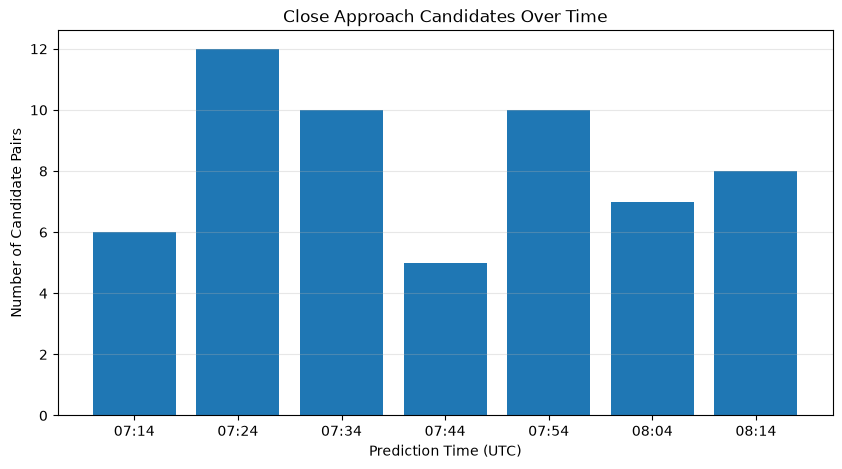

In [339]:
#Visualize candidate counts over time 
plt.figure(figsize=(10, 5))

plt.bar(
    timestamp_summary["prediction_time_utc"].dt.strftime("%H:%M"),
    timestamp_summary["candidate_count"]
)

plt.title("Close Approach Candidates Over Time")
plt.xlabel("Prediction Time (UTC)")
plt.ylabel("Number of Candidate Pairs")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [340]:
#Identify repeatedly appearing candidate pairs
repeated_pairs = (
    pair_summary[
        pair_summary["observation_count"] > 1
    ]
    .sort_values(
        by="observation_count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(repeated_pairs)


,object_A_id,object_B_id,object_A_name,object_B_name,minimum_separation_km,maximum_separation_km,observation_count
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,9.900489,35.143572,7
1,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,40.636882,84.225931,7
2,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,49.847261,79.985302,4
3,34273,34547,COSMOS 2251 DEB,COSMOS 2251 DEB,53.317974,90.292265,3
4,35614,35885,COSMOS 2251 DEB,COSMOS 2251 DEB,58.502498,75.596344,3
5,35836,36558,COSMOS 2251 DEB,COSMOS 2251 DEB,68.270914,91.480386,3
6,34303,37293,COSMOS 2251 DEB,COSMOS 2251 DEB,80.435137,92.070392,3
7,34014,34681,COSMOS 2251 DEB,COSMOS 2251 DEB,68.612831,84.751246,2
8,35956,36367,COSMOS 2251 DEB,COSMOS 2251 DEB,70.700263,90.691830,2
9,34387,34796,COSMOS 2251 DEB,COSMOS 2251 DEB,72.304247,74.750667,2


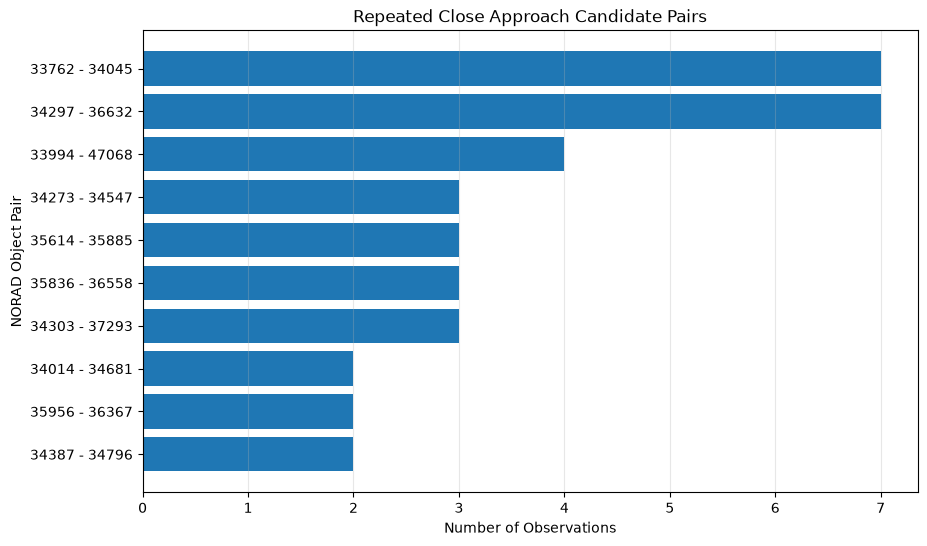

In [341]:
#Visualize repeated pairs
plt.figure(figsize=(10, 6))

pair_labels = (
    repeated_pairs["object_A_id"].astype(str)
    + " - "
    + repeated_pairs["object_B_id"].astype(str)
)

plt.barh(
    pair_labels,
    repeated_pairs["observation_count"]
)

plt.title("Repeated Close Approach Candidate Pairs")
plt.xlabel("Number of Observations")
plt.ylabel("NORAD Object Pair")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

In [342]:
#Risk screening start
print(close_approach_report.columns.tolist())

['object_A_id', 'object_B_id', 'object_A_name', 'object_B_name', 'prediction_time_utc', 'separation_km', 'relative_speed_km_s', 'separation_rate_km_s', 'motion_status', 'observation_count']


In [343]:
#Inspect the data before classification
print("Separation range:")
print(close_approach_report["separation_km"].min())
print(close_approach_report["separation_km"].max())

print("\nRelative speed range:")
print(close_approach_report["relative_speed_km_s"].min())
print(close_approach_report["relative_speed_km_s"].max())

print("\nMotion status:")
print(close_approach_report["motion_status"].value_counts())


Separation range:
9.900489328772451
95.50789151937356

Relative speed range:
0.029064118897584614
14.530745986089604

Motion status:
motion_status
RECEDING       20
APPROACHING    12
Name: count, dtype: int64


In [344]:
#Create separation categories
def classify_separation(distance):

    if distance <= 20:
        return "VERY_CLOSE"

    elif distance <= 50:
        return "CLOSE"

    else:
        return "MODERATE"


close_approach_report["separation_category"] = (
    close_approach_report["separation_km"]
    .apply(classify_separation)
)

display(
    close_approach_report[
        ["object_A_id", "object_B_id",
         "separation_km", "separation_category"]
    ].head(10)
)


,object_A_id,object_B_id,separation_km,separation_category
0,33762,34045,9.900489,VERY_CLOSE
1,34571,34635,33.149825,CLOSE
2,33766,37483,33.199266,CLOSE
3,34297,36632,40.636882,CLOSE
4,33994,47068,49.847261,CLOSE
5,34273,34547,53.317974,MODERATE
6,34635,34953,58.146888,MODERATE
7,35614,35885,58.502498,MODERATE
8,34944,35060,58.511774,MODERATE
9,33797,38055,60.986675,MODERATE


In [345]:
#Check the complete category distribution
separation_summary = (
    close_approach_report["separation_category"]
    .value_counts()
    .reset_index()
)

separation_summary.columns = [
    "separation_category",
    "pair_count"
]

display(separation_summary)

,separation_category,pair_count
0,MODERATE,27
1,CLOSE,4
2,VERY_CLOSE,1


In [346]:
#Classify relative speed
def classify_relative_speed(speed):

    if speed >= 5:
        return "HIGHER_RELATIVE_SPEED"

    else:
        return "LOWER_RELATIVE_SPEED"


close_approach_report["speed_category"] = (
    close_approach_report["relative_speed_km_s"]
    .apply(classify_relative_speed)
)

display(
    close_approach_report[
        ["object_A_id", "object_B_id",
         "relative_speed_km_s", "speed_category"]
    ].head(10)
)

,object_A_id,object_B_id,relative_speed_km_s,speed_category
0,33762,34045,0.037998,LOWER_RELATIVE_SPEED
1,34571,34635,13.076509,HIGHER_RELATIVE_SPEED
2,33766,37483,0.900670,LOWER_RELATIVE_SPEED
3,34297,36632,0.053263,LOWER_RELATIVE_SPEED
4,33994,47068,0.033657,LOWER_RELATIVE_SPEED
5,34273,34547,0.062160,LOWER_RELATIVE_SPEED
6,34635,34953,5.143874,HIGHER_RELATIVE_SPEED
7,35614,35885,0.029064,LOWER_RELATIVE_SPEED
8,34944,35060,0.408432,LOWER_RELATIVE_SPEED
9,33797,38055,14.063971,HIGHER_RELATIVE_SPEED


In [347]:
#Count the speed categories
speed_summary = (
    close_approach_report["speed_category"]
    .value_counts()
    .reset_index()
)

speed_summary.columns = [
    "speed_category",
    "pair_count"
]

display(speed_summary)

,speed_category,pair_count
0,LOWER_RELATIVE_SPEED,24
1,HIGHER_RELATIVE_SPEED,8


In [348]:
#Combine separation and speed categories
risk_factor_summary = pd.crosstab(
    close_approach_report["separation_category"],
    close_approach_report["speed_category"]
)

display(risk_factor_summary)

speed_category,HIGHER_RELATIVE_SPEED,LOWER_RELATIVE_SPEED
separation_category,,
CLOSE,1,3
MODERATE,7,20
VERY_CLOSE,0,1


In [349]:
#Add motion status to the combined analysis
motion_factor_summary = pd.crosstab(
    [
        close_approach_report["separation_category"],
        close_approach_report["speed_category"]
    ],
    close_approach_report["motion_status"]
)

display(motion_factor_summary)


motion_status                              APPROACHING  RECEDING
separation_category speed_category                              
CLOSE               HIGHER_RELATIVE_SPEED            1         0
                    LOWER_RELATIVE_SPEED             1         2
MODERATE            HIGHER_RELATIVE_SPEED            2         5
                    LOWER_RELATIVE_SPEED             7        13
VERY_CLOSE          LOWER_RELATIVE_SPEED             1         0

In [350]:
#Create preliminary review-priority categories
def assign_review_priority(row):

    if row["motion_status"] == "RECEDING":
        return "MONITOR"

    elif row["separation_km"] <= 20:
        return "PRIORITY_1"

    elif row["separation_km"] <= 50:
        return "PRIORITY_2"

    else:
        return "PRIORITY_3"


close_approach_report["review_priority"] = (
    close_approach_report.apply(
        assign_review_priority,
        axis=1
    )
)

display(
    close_approach_report[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_speed_km_s",
            "motion_status",
            "review_priority"
        ]
    ].head(15)
)

,object_A_id,object_B_id,separation_km,relative_speed_km_s,motion_status,review_priority
0,33762,34045,9.900489,0.037998,APPROACHING,PRIORITY_1
1,34571,34635,33.149825,13.076509,APPROACHING,PRIORITY_2
2,33766,37483,33.199266,0.900670,APPROACHING,PRIORITY_2
3,34297,36632,40.636882,0.053263,RECEDING,MONITOR
4,33994,47068,49.847261,0.033657,RECEDING,MONITOR
5,34273,34547,53.317974,0.062160,RECEDING,MONITOR
6,34635,34953,58.146888,5.143874,APPROACHING,PRIORITY_3
7,35614,35885,58.502498,0.029064,APPROACHING,PRIORITY_3
8,34944,35060,58.511774,0.408432,APPROACHING,PRIORITY_3
9,33797,38055,60.986675,14.063971,RECEDING,MONITOR


In [351]:
#Count all review priorities
priority_summary = (
    close_approach_report["review_priority"]
    .value_counts()
    .reset_index()
)

priority_summary.columns = [
    "review_priority",
    "pair_count"
]

display(priority_summary)

,review_priority,pair_count
0,MONITOR,20
1,PRIORITY_3,9
2,PRIORITY_2,2
3,PRIORITY_1,1


In [352]:
#Inspect Priority 1 and Priority 2 pairs
high_priority_pairs = (
    close_approach_report[
        close_approach_report["review_priority"].isin(
            ["PRIORITY_1", "PRIORITY_2"]
        )
    ]
    .sort_values(
        by=["review_priority", "separation_km"]
    )
    .reset_index(drop=True)
)

display(high_priority_pairs)

,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count,separation_category,speed_category,review_priority
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING,7,VERY_CLOSE,LOWER_RELATIVE_SPEED,PRIORITY_1
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1,CLOSE,HIGHER_RELATIVE_SPEED,PRIORITY_2
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.199266,0.900670,-0.812134,APPROACHING,1,CLOSE,LOWER_RELATIVE_SPEED,PRIORITY_2


In [353]:
#Check the priority distrbution by speed
priority_speed_summary = pd.crosstab(
    close_approach_report["review_priority"],
    close_approach_report["speed_category"]
)

display(priority_speed_summary)

speed_category,HIGHER_RELATIVE_SPEED,LOWER_RELATIVE_SPEED
review_priority,,
MONITOR,5,15
PRIORITY_1,0,1
PRIORITY_2,1,1
PRIORITY_3,2,7


In [354]:
#Add an independent speed-review flag
def assign_speed_review(speed):
    if speed >= 5:
        return "HIGH_SPEED_REVIEW"
    else:
        return "NORMAL_SPEED_REVIEW"


close_approach_report["speed_review_flag"] = (
    close_approach_report["relative_speed_km_s"]
    .apply(assign_speed_review)
)

display(
    close_approach_report[
        [
            "object_A_id",
            "object_B_id",
            "separation_km",
            "relative_speed_km_s",
            "motion_status",
            "review_priority",
            "speed_review_flag"
        ]
    ].head(10)
)

,object_A_id,object_B_id,separation_km,relative_speed_km_s,motion_status,review_priority,speed_review_flag
0,33762,34045,9.900489,0.037998,APPROACHING,PRIORITY_1,NORMAL_SPEED_REVIEW
1,34571,34635,33.149825,13.076509,APPROACHING,PRIORITY_2,HIGH_SPEED_REVIEW
2,33766,37483,33.199266,0.900670,APPROACHING,PRIORITY_2,NORMAL_SPEED_REVIEW
3,34297,36632,40.636882,0.053263,RECEDING,MONITOR,NORMAL_SPEED_REVIEW
4,33994,47068,49.847261,0.033657,RECEDING,MONITOR,NORMAL_SPEED_REVIEW
5,34273,34547,53.317974,0.062160,RECEDING,MONITOR,NORMAL_SPEED_REVIEW
6,34635,34953,58.146888,5.143874,APPROACHING,PRIORITY_3,HIGH_SPEED_REVIEW
7,35614,35885,58.502498,0.029064,APPROACHING,PRIORITY_3,NORMAL_SPEED_REVIEW
8,34944,35060,58.511774,0.408432,APPROACHING,PRIORITY_3,NORMAL_SPEED_REVIEW
9,33797,38055,60.986675,14.063971,RECEDING,MONITOR,HIGH_SPEED_REVIEW


In [355]:
#Inspect every high-speed pair
high_speed_pairs = (
    close_approach_report[
        close_approach_report["speed_review_flag"] == "HIGH_SPEED_REVIEW"
    ]
    .sort_values(
        by="relative_speed_km_s",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    high_speed_pairs[
        [
            "object_A_id",
            "object_B_id",
            "prediction_time_utc",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s",
            "motion_status",
            "review_priority",
            "speed_review_flag"
        ]
    ]
)


,object_A_id,object_B_id,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,review_priority,speed_review_flag
0,35759,35786,2026-10-26 07:24:37.419912+00:00,65.926493,14.530746,5.738404,RECEDING,MONITOR,HIGH_SPEED_REVIEW
1,35456,38067,2026-10-26 08:14:37.419912+00:00,95.507892,14.384705,12.928335,RECEDING,MONITOR,HIGH_SPEED_REVIEW
2,35015,39110,2026-10-26 07:24:37.419912+00:00,93.158093,14.344542,4.339527,RECEDING,MONITOR,HIGH_SPEED_REVIEW
3,33797,38055,2026-10-26 08:04:37.419912+00:00,60.986675,14.063971,3.837172,RECEDING,MONITOR,HIGH_SPEED_REVIEW
4,34571,34635,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,PRIORITY_2,HIGH_SPEED_REVIEW
5,33932,34563,2026-10-26 07:54:37.419912+00:00,80.013270,12.392360,-7.377782,APPROACHING,PRIORITY_3,HIGH_SPEED_REVIEW
6,33942,35434,2026-10-26 07:24:37.419912+00:00,90.251185,6.029308,5.688703,RECEDING,MONITOR,HIGH_SPEED_REVIEW
7,34635,34953,2026-10-26 07:24:37.419912+00:00,58.146888,5.143874,-2.650539,APPROACHING,PRIORITY_3,HIGH_SPEED_REVIEW


In [356]:
#Create a combined screening summary
combined_screening_summary = (
    close_approach_report
    .groupby(
        ["review_priority", "speed_review_flag"]
    )
    .agg(
        pair_count=("object_A_id", "count"),
        minimum_separation_km=("separation_km", "min"),
        maximum_relative_speed_km_s=("relative_speed_km_s", "max")
    )
    .reset_index()
)

display(combined_screening_summary)


,review_priority,speed_review_flag,pair_count,minimum_separation_km,maximum_relative_speed_km_s
0,MONITOR,HIGH_SPEED_REVIEW,5,60.986675,14.530746
1,MONITOR,NORMAL_SPEED_REVIEW,15,40.636882,4.074052
2,PRIORITY_1,NORMAL_SPEED_REVIEW,1,9.900489,0.037998
3,PRIORITY_2,HIGH_SPEED_REVIEW,1,33.149825,13.076509
4,PRIORITY_2,NORMAL_SPEED_REVIEW,1,33.199266,0.900670
5,PRIORITY_3,HIGH_SPEED_REVIEW,2,58.146888,12.392360
6,PRIORITY_3,NORMAL_SPEED_REVIEW,7,58.502498,2.149686


In [357]:
#Save the final screening report 
close_approach_report.to_csv(
    "close_approach_screening_report.csv",
    index=False
)

print("Screening report saved successfully!")

print("Rows:", len(close_approach_report))
print("Columns:", len(close_approach_report.columns))

print("\nColumns:")
print(close_approach_report.columns.tolist())


Screening report saved successfully!
Rows: 32
Columns: 14

Columns:
['object_A_id', 'object_B_id', 'object_A_name', 'object_B_name', 'prediction_time_utc', 'separation_km', 'relative_speed_km_s', 'separation_rate_km_s', 'motion_status', 'observation_count', 'separation_category', 'speed_category', 'review_priority', 'speed_review_flag']


In [358]:
#Verify the saved report
verified_report = pd.read_csv("close_approach_screening_report.csv")

print("Verification successful:", verified_report.shape == close_approach_report.shape)
print("Shape:", verified_report.shape)
print("Missing values:", verified_report.isnull().sum().sum())
print("Duplicate rows:", verified_report.duplicated().sum())

display(verified_report.head())

Verification successful: True
Shape: (32, 14)
Missing values: 0
Duplicate rows: 0


,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count,separation_category,speed_category,review_priority,speed_review_flag
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING,7,VERY_CLOSE,LOWER_RELATIVE_SPEED,PRIORITY_1,NORMAL_SPEED_REVIEW
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1,CLOSE,HIGHER_RELATIVE_SPEED,PRIORITY_2,HIGH_SPEED_REVIEW
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.199266,0.900670,-0.812134,APPROACHING,1,CLOSE,LOWER_RELATIVE_SPEED,PRIORITY_2,NORMAL_SPEED_REVIEW
3,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,40.636882,0.053263,0.000772,RECEDING,7,CLOSE,LOWER_RELATIVE_SPEED,MONITOR,NORMAL_SPEED_REVIEW
4,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,49.847261,0.033657,0.022098,RECEDING,4,CLOSE,LOWER_RELATIVE_SPEED,MONITOR,NORMAL_SPEED_REVIEW


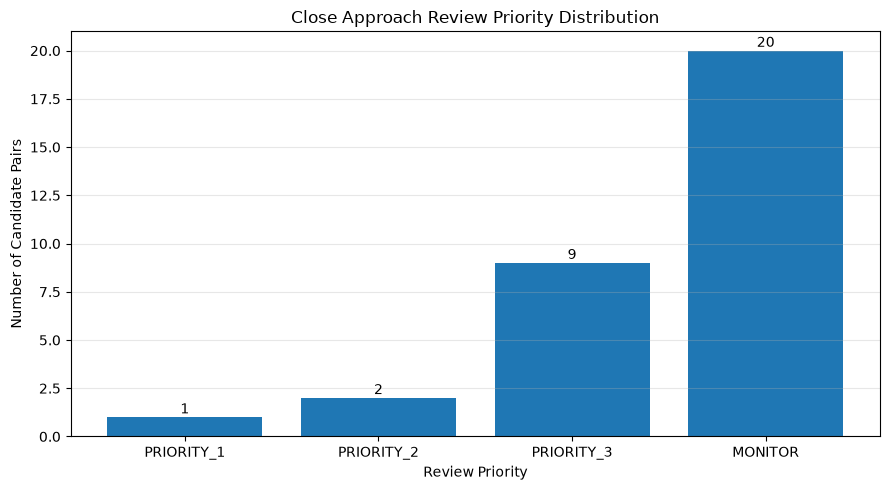

In [359]:
#Final visualization of screening results
# Review priority distribution
import matplotlib.pyplot as plt

priority_counts = (
    close_approach_report["review_priority"]
    .value_counts()
    .reindex(
        ["PRIORITY_1", "PRIORITY_2", "PRIORITY_3", "MONITOR"],
        fill_value=0
    )
)

plt.figure(figsize=(9, 5))

plt.bar(
    priority_counts.index,
    priority_counts.values
)

plt.title("Close Approach Review Priority Distribution")
plt.xlabel("Review Priority")
plt.ylabel("Number of Candidate Pairs")
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(priority_counts.values):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.tight_layout()
plt.show()

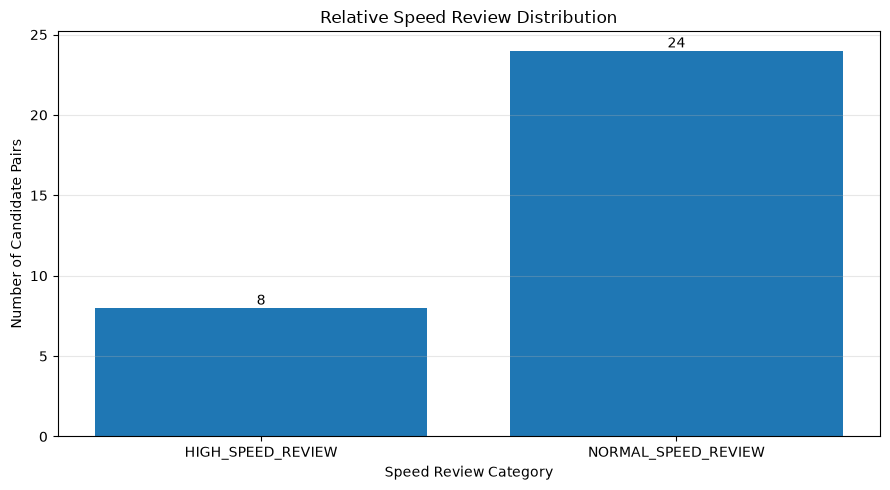

In [360]:
#speed-review distribution
speed_counts = (
    close_approach_report["speed_review_flag"]
    .value_counts()
    .reindex(
        ["HIGH_SPEED_REVIEW", "NORMAL_SPEED_REVIEW"],
        fill_value=0
    )
)

plt.figure(figsize=(9, 5))

plt.bar(speed_counts.index, speed_counts.values)

plt.title("Relative Speed Review Distribution")
plt.xlabel("Speed Review Category")
plt.ylabel("Number of Candidate Pairs")

for i, value in enumerate(speed_counts.values):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

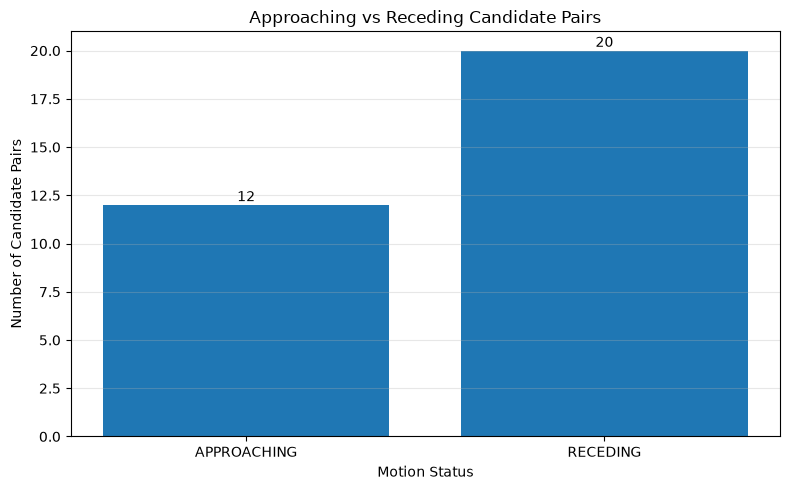

In [361]:
#Approaching vs receding distribution
motion_counts = (
    close_approach_report["motion_status"]
    .value_counts()
    .reindex(
        ["APPROACHING", "RECEDING"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 5))

plt.bar(motion_counts.index, motion_counts.values)

plt.title("Approaching vs Receding Candidate Pairs")
plt.xlabel("Motion Status")
plt.ylabel("Number of Candidate Pairs")

for i, value in enumerate(motion_counts.values):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


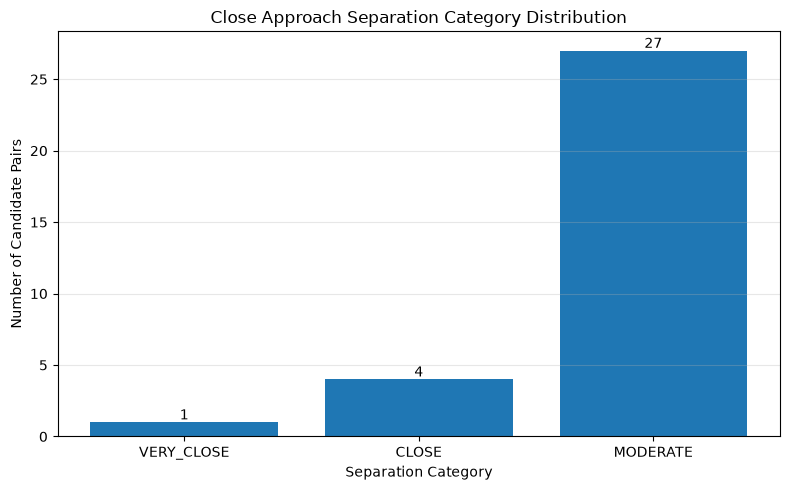

In [362]:
#separation category distribution
separation_counts = (
    close_approach_report["separation_category"]
    .value_counts()
    .reindex(
        ["VERY_CLOSE", "CLOSE", "MODERATE"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 5))

plt.bar(separation_counts.index, separation_counts.values)

plt.title("Close Approach Separation Category Distribution")
plt.xlabel("Separation Category")
plt.ylabel("Number of Candidate Pairs")

for i, value in enumerate(separation_counts.values):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

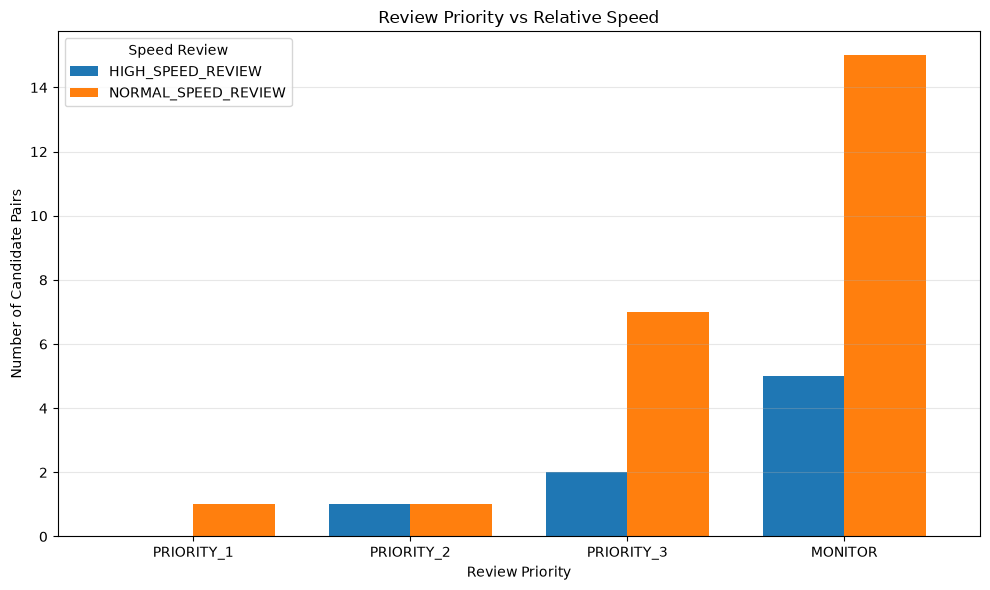

In [363]:
#Review priority vs relative speed
priority_speed_summary = pd.crosstab(
    close_approach_report["review_priority"],
    close_approach_report["speed_review_flag"]
)

priority_speed_summary = priority_speed_summary.reindex(
    ["PRIORITY_1", "PRIORITY_2", "PRIORITY_3", "MONITOR"],
    fill_value=0
)

ax = priority_speed_summary.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Review Priority vs Relative Speed")
ax.set_xlabel("Review Priority")
ax.set_ylabel("Number of Candidate Pairs")
ax.legend(title="Speed Review")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


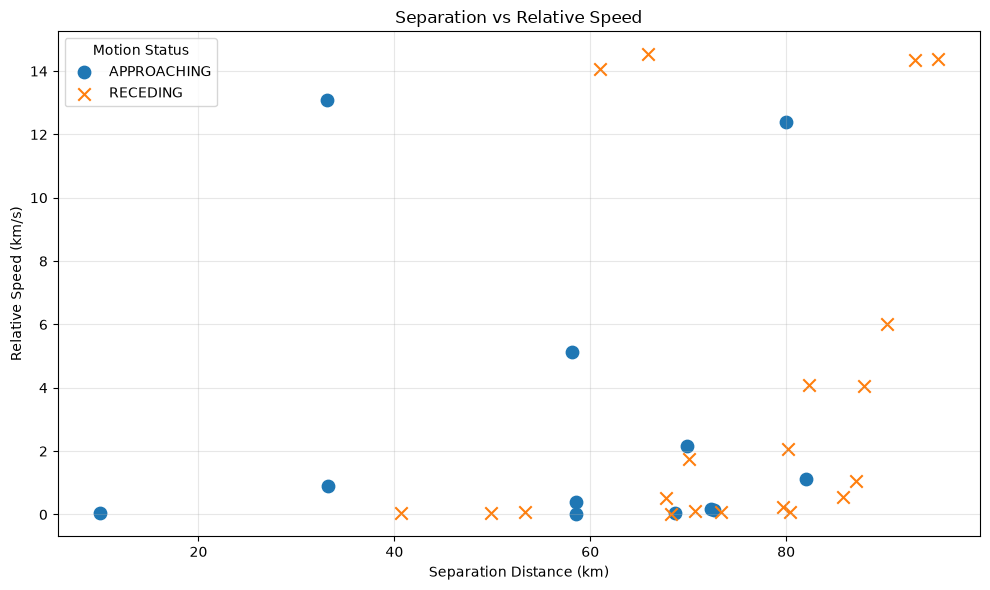

In [364]:
#separtation vs relative speed scatter plot
plt.figure(figsize=(10, 6))

for status, marker in [
    ("APPROACHING", "o"),
    ("RECEDING", "x")
]:
    subset = close_approach_report[
        close_approach_report["motion_status"] == status
    ]

    plt.scatter(
        subset["separation_km"],
        subset["relative_speed_km_s"],
        label=status,
        marker=marker,
        s=80
    )

plt.title("Separation vs Relative Speed")
plt.xlabel("Separation Distance (km)")
plt.ylabel("Relative Speed (km/s)")
plt.legend(title="Motion Status")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

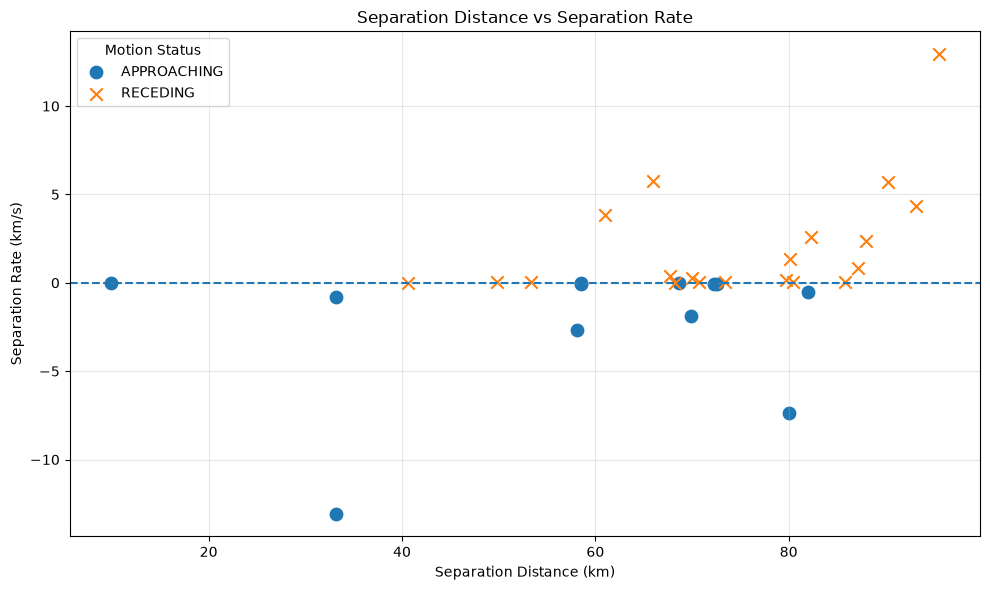

In [365]:
#Separation rate vs separation distance
plt.figure(figsize=(10, 6))

for status, marker in [
    ("APPROACHING", "o"),
    ("RECEDING", "x")
]:
    subset = close_approach_report[
        close_approach_report["motion_status"] == status
    ]

    plt.scatter(
        subset["separation_km"],
        subset["separation_rate_km_s"],
        label=status,
        marker=marker,
        s=80
    )

plt.axhline(y=0, linestyle="--")

plt.title("Separation Distance vs Separation Rate")
plt.xlabel("Separation Distance (km)")
plt.ylabel("Separation Rate (km/s)")
plt.legend(title="Motion Status")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [366]:
#Idenfity the fastest-chaning candidate pairs
fastest_changing_pairs = (
    close_approach_report.assign(
        absolute_separation_rate=lambda x:
        x["separation_rate_km_s"].abs()
    )
    .nlargest(10, "absolute_separation_rate")
    .copy()
)

fastest_changing_pairs["pair"] = (
    fastest_changing_pairs["object_A_id"].astype(str)
    + " - "
    + fastest_changing_pairs["object_B_id"].astype(str)
)

display(
    fastest_changing_pairs[
        [
            "pair",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s",
            "motion_status"
        ]
    ]
)

,pair,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status
1,34571 - 34635,33.149825,13.076509,-13.056323,APPROACHING
31,35456 - 38067,95.507892,14.384705,12.928335,RECEDING
21,33932 - 34563,80.013270,12.392360,-7.377782,APPROACHING
10,35759 - 35786,65.926493,14.530746,5.738404,RECEDING
29,33942 - 35434,90.251185,6.029308,5.688703,RECEDING
30,35015 - 39110,93.158093,14.344542,4.339527,RECEDING
9,33797 - 38055,60.986675,14.063971,3.837172,RECEDING
6,34635 - 34953,58.146888,5.143874,-2.650539,APPROACHING
25,35671 - 37959,82.294337,4.074052,2.589415,RECEDING
28,34883 - 36005,87.975014,4.048205,2.348063,RECEDING


In [367]:
#Compare different screening thresholds
from scipy.spatial.distance import pdist

thresholds = [50, 100, 200, 500]

threshold_results = []

for threshold in thresholds:

    total_observations = 0

    for timestamp in sorted(
        analysis_df["prediction_time_utc"].unique()
    ):

        current_df = analysis_df[
            analysis_df["prediction_time_utc"] == timestamp
        ]

        positions = current_df[
            ["x_teme_km", "y_teme_km", "z_teme_km"]
        ].to_numpy()

        distances = pdist(positions, metric="euclidean")

        candidate_count = np.sum(distances < threshold)

        total_observations += candidate_count

    threshold_results.append({
        "threshold_km": threshold,
        "candidate_observations": total_observations
    })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary)

,threshold_km,candidate_observations
0,50,13
1,100,58
2,200,241
3,500,1808


In [368]:
#important ditinction: observations vs unique pairs
from scipy.spatial.distance import pdist

thresholds = [50, 100, 200, 500]

threshold_results = []

for threshold in thresholds:

    total_observations = 0
    unique_pairs = set()

    for timestamp in sorted(
        analysis_df["prediction_time_utc"].unique()
    ):

        current_df = analysis_df[
            analysis_df["prediction_time_utc"] == timestamp
        ].reset_index(drop=True)

        positions = current_df[
            ["x_teme_km", "y_teme_km", "z_teme_km"]
        ].to_numpy()

        distances = pdist(positions, metric="euclidean")

        pair_indices = np.triu_indices(len(current_df), k=1)

        close_mask = distances < threshold

        total_observations += np.sum(close_mask)

        ids_A = current_df.iloc[
            pair_indices[0]
        ]["norad_cat_id"].to_numpy()

        ids_B = current_df.iloc[
            pair_indices[1]
        ]["norad_cat_id"].to_numpy()

        for id_A, id_B in zip(ids_A[close_mask], ids_B[close_mask]):
            unique_pairs.add(tuple(sorted((int(id_A), int(id_B)))))

    threshold_results.append({
        "threshold_km": threshold,
        "candidate_observations": total_observations,
        "unique_candidate_pairs": len(unique_pairs)
    })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary)

,threshold_km,candidate_observations,unique_candidate_pairs
0,50,13,5
1,100,58,32
2,200,241,166
3,500,1808,1245


In [369]:
#how much of the total pair population are we screening?
total_possible_pairs = 580 * 579 // 2

threshold_summary["percentage_of_pairs"] = (
    threshold_summary["unique_candidate_pairs"]
    / total_possible_pairs
) * 100

display(threshold_summary)

,threshold_km,candidate_observations,unique_candidate_pairs,percentage_of_pairs
0,50,13,5,0.002978
1,100,58,32,0.019058
2,200,241,166,0.098862
3,500,1808,1245,0.741469


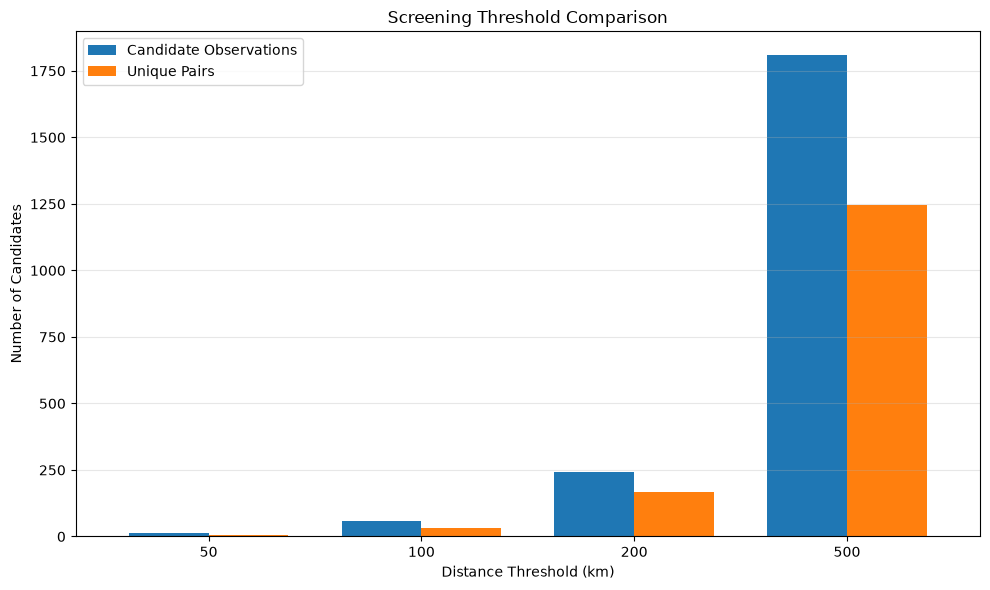

In [370]:
#Visualize threshold compairison
threshold_plot = threshold_summary.set_index("threshold_km")

ax = threshold_plot[
    ["candidate_observations", "unique_candidate_pairs"]
].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Screening Threshold Comparison")
ax.set_xlabel("Distance Threshold (km)")
ax.set_ylabel("Number of Candidates")
ax.legend(["Candidate Observations", "Unique Pairs"])
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [371]:
#compare threshold over time
thresholds = [50, 100, 200, 500]

threshold_time_results = []

for threshold in thresholds:

    for timestamp in sorted(analysis_df["prediction_time_utc"].unique()):

        current_df = analysis_df[
            analysis_df["prediction_time_utc"] == timestamp
        ].reset_index(drop=True)

        positions = current_df[
            ["x_teme_km", "y_teme_km", "z_teme_km"]
        ].to_numpy()

        distances = pdist(positions, metric="euclidean")

        candidate_count = np.sum(distances < threshold)

        threshold_time_results.append({
            "prediction_time_utc": timestamp,
            "threshold_km": threshold,
            "candidate_count": candidate_count
        })

threshold_time_summary = pd.DataFrame(threshold_time_results)

display(threshold_time_summary.head(12))

,prediction_time_utc,threshold_km,candidate_count
0,2026-10-26 07:14:37.419912+00:00,50,1
1,2026-10-26 07:24:37.419912+00:00,50,2
2,2026-10-26 07:34:37.419912+00:00,50,4
3,2026-10-26 07:44:37.419912+00:00,50,2
4,2026-10-26 07:54:37.419912+00:00,50,1
5,2026-10-26 08:04:37.419912+00:00,50,2
6,2026-10-26 08:14:37.419912+00:00,50,1
7,2026-10-26 07:14:37.419912+00:00,100,6
8,2026-10-26 07:24:37.419912+00:00,100,12
9,2026-10-26 07:34:37.419912+00:00,100,10


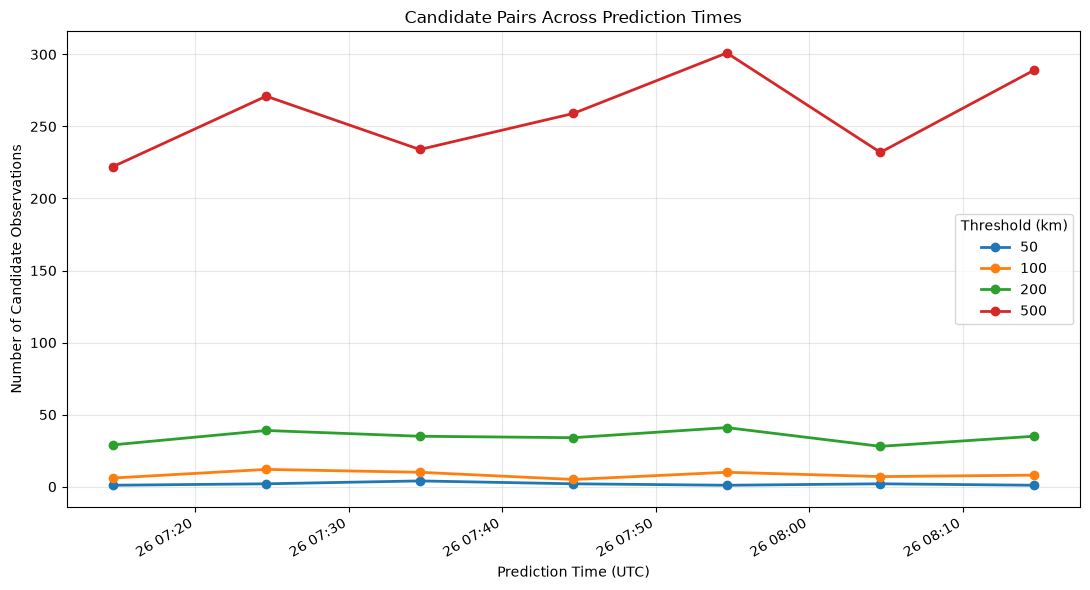

In [372]:
#create a comparison chart
threshold_chart_data = threshold_time_summary.pivot(
    index="prediction_time_utc",
    columns="threshold_km",
    values="candidate_count"
)

ax = threshold_chart_data.plot(
    kind="line",
    marker="o",
    figsize=(11, 6),
    linewidth=2
)

ax.set_title("Candidate Pairs Across Prediction Times")
ax.set_xlabel("Prediction Time (UTC)")
ax.set_ylabel("Number of Candidate Observations")
ax.legend(title="Threshold (km)")
ax.grid(alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [373]:
#calculate threshold statistics
threshold_statistics = (
    threshold_time_summary
    .groupby("threshold_km")
    .agg(
        minimum_candidates=("candidate_count", "min"),
        maximum_candidates=("candidate_count", "max"),
        average_candidates=("candidate_count", "mean"),
        total_observations=("candidate_count", "sum")
    )
    .reset_index()
)

display(threshold_statistics.round(2))

,threshold_km,minimum_candidates,maximum_candidates,average_candidates,total_observations
0,50,1,4,1.86,13
1,100,5,12,8.29,58
2,200,28,41,34.43,241
3,500,222,301,258.29,1808


In [374]:
#combine all threshold results
threshold_comparison_report = threshold_statistics.merge(
    threshold_summary[
        [
            "threshold_km",
            "unique_candidate_pairs",
            "percentage_of_pairs"
        ]
    ],
    on="threshold_km",
    how="left"
)

threshold_comparison_report = threshold_comparison_report.sort_values(
    "threshold_km"
).reset_index(drop=True)

display(threshold_comparison_report.round(3))

,threshold_km,minimum_candidates,maximum_candidates,average_candidates,total_observations,unique_candidate_pairs,percentage_of_pairs
0,50,1,4,1.857,13,5,0.003
1,100,5,12,8.286,58,32,0.019
2,200,28,41,34.429,241,166,0.099
3,500,222,301,258.286,1808,1245,0.741


In [375]:
#Save the consolidated report
threshold_comparison_report.to_csv(
    "threshold_comparison_report.csv",
    index=False
)

print("Threshold comparison report saved successfully!")

print("Rows:", len(threshold_comparison_report))
print("Columns:", len(threshold_comparison_report.columns))


Threshold comparison report saved successfully!
Rows: 4
Columns: 7


In [376]:
#Verify saved report
verified_threshold_report = pd.read_csv(
    "threshold_comparison_report.csv"
)

print("Shape:", verified_threshold_report.shape)
print("Missing values:", verified_threshold_report.isnull().sum().sum())
print("Duplicate rows:", verified_threshold_report.duplicated().sum())

display(verified_threshold_report)

Shape: (4, 7)
Missing values: 0
Duplicate rows: 0


,threshold_km,minimum_candidates,maximum_candidates,average_candidates,total_observations,unique_candidate_pairs,percentage_of_pairs
0,50,1,4,1.857143,13,5,0.002978
1,100,5,12,8.285714,58,32,0.019058
2,200,28,41,34.428571,241,166,0.098862
3,500,222,301,258.285714,1808,1245,0.741469


In [377]:
#Prepare dashboard-ready data
print("Candidate motion columns:")
print(candidate_motion.columns.tolist())

print("\nOrbital quality report columns:")
print(final_quality_report.columns.tolist())

Candidate motion columns:
['prediction_time_utc', 'object_A_id', 'object_B_id', 'object_A_name', 'object_B_name', 'separation_km', 'observation_count', 'x_A', 'y_A', 'z_A', 'vx_A', 'vy_A', 'vz_A', 'x_B', 'y_B', 'z_B', 'vx_B', 'vy_B', 'vz_B', 'relative_vx', 'relative_vy', 'relative_vz', 'relative_speed_km_s', 'relative_rx', 'relative_ry', 'relative_rz', 'position_velocity_dot', 'separation_rate_km_s', 'motion_status']

Orbital quality report columns:
['norad_cat_id', 'object_name', 'element_age_hours', 'data_quality_status', 'low_position_flag', 'position_quality_status', 'min_position_km', 'max_position_km', 'min_speed_km_s', 'max_speed_km_s', 'min_approx_altitude_km']


In [378]:
#prepare Object A quality information
quality_A = final_quality_report[
    [
        "norad_cat_id",
        "element_age_hours",
        "data_quality_status",
        "position_quality_status",
        "min_approx_altitude_km"
    ]
].copy()

quality_A = quality_A.rename(columns={
    "norad_cat_id": "object_A_id",
    "element_age_hours": "object_A_element_age_hours",
    "data_quality_status": "object_A_data_quality",
    "position_quality_status": "object_A_position_quality",
    "min_approx_altitude_km": "object_A_min_altitude_km"
})

display(quality_A.head())


,object_A_id,object_A_element_age_hours,object_A_data_quality,object_A_position_quality,object_A_min_altitude_km
0,33757,120.963651,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,775.045948
1,33758,123.777531,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,714.595530
2,33760,119.152617,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,762.162056
3,33761,121.252981,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,736.026835
4,33762,129.459534,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,768.939235


In [379]:
#Prepare Object B quality information
quality_B = final_quality_report[
    [
        "norad_cat_id",
        "element_age_hours",
        "data_quality_status",
        "position_quality_status",
        "min_approx_altitude_km"
    ]
].copy()

quality_B = quality_B.rename(columns={
    "norad_cat_id": "object_B_id",
    "element_age_hours": "object_B_element_age_hours",
    "data_quality_status": "object_B_data_quality",
    "position_quality_status": "object_B_position_quality",
    "min_approx_altitude_km": "object_B_min_altitude_km"
})

display(quality_B.head())

,object_B_id,object_B_element_age_hours,object_B_data_quality,object_B_position_quality,object_B_min_altitude_km
0,33757,120.963651,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,775.045948
1,33758,123.777531,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,714.595530
2,33760,119.152617,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,762.162056
3,33761,121.252981,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,736.026835
4,33762,129.459534,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,768.939235


In [380]:
#Combine Object A quality with candidate pairs 
candidate_quality = candidate_motion.merge(
    quality_A,
    on="object_A_id",
    how="left"
)

print("Original candidate pairs:", len(candidate_motion))
print("After Object A quality merge:", len(candidate_quality))

print("\nMissing Object A quality values:")
print(candidate_quality["object_A_data_quality"].isna().sum())

display(candidate_quality.head())

Original candidate pairs: 32
After Object A quality merge: 32

Missing Object A quality values:
0


,prediction_time_utc,object_A_id,object_B_id,object_A_name,object_B_name,separation_km,observation_count,x_A,y_A,z_A,...,relative_rx,relative_ry,relative_rz,position_velocity_dot,separation_rate_km_s,motion_status,object_A_element_age_hours,object_A_data_quality,object_A_position_quality,object_A_min_altitude_km
0,2026-10-26 08:14:37.419912+00:00,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,9.900489,7,-1946.695936,727.618430,6830.789020,...,-1.177312,-2.099101,-9.603510,-0.059746,-0.006035,APPROACHING,129.459534,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,768.939235
1,2026-10-26 07:34:37.419912+00:00,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,33.149825,1,-3405.596358,1994.295466,-5848.830190,...,24.710000,-12.318199,-18.346356,-432.814805,-13.056323,APPROACHING,101.530884,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,682.450031
2,2026-10-26 07:34:37.419912+00:00,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,33.199266,1,-2013.463446,312.387199,-6887.134999,...,29.440527,15.100084,-2.726554,-26.962263,-0.812134,APPROACHING,141.371303,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,733.868438
3,2026-10-26 07:34:37.419912+00:00,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,40.636882,7,524.851768,-2902.734997,-6529.810620,...,11.582107,38.949897,-0.341245,0.031391,0.000772,RECEDING,77.170319,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,762.572820
4,2026-10-26 08:04:37.419912+00:00,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,49.847261,4,-5644.080729,4384.796577,190.184798,...,42.682165,-23.670393,-10.133840,1.101530,0.022098,RECEDING,76.474421,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,743.360210


In [381]:
#Attach Object B quality information
candidate_quality = candidate_quality.merge(
    quality_B,
    on="object_B_id",
    how="left"
)

print("Candidate pairs:", len(candidate_quality))
print("Total columns:", len(candidate_quality.columns))

print("\nMissing Object B quality values:")
print(candidate_quality["object_B_data_quality"].isna().sum())

display(candidate_quality.head())


Candidate pairs: 32
Total columns: 37

Missing Object B quality values:
0


,prediction_time_utc,object_A_id,object_B_id,object_A_name,object_B_name,separation_km,observation_count,x_A,y_A,z_A,...,separation_rate_km_s,motion_status,object_A_element_age_hours,object_A_data_quality,object_A_position_quality,object_A_min_altitude_km,object_B_element_age_hours,object_B_data_quality,object_B_position_quality,object_B_min_altitude_km
0,2026-10-26 08:14:37.419912+00:00,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,9.900489,7,-1946.695936,727.618430,6830.789020,...,-0.006035,APPROACHING,129.459534,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,768.939235,82.571272,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,759.859713
1,2026-10-26 07:34:37.419912+00:00,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,33.149825,1,-3405.596358,1994.295466,-5848.830190,...,-13.056323,APPROACHING,101.530884,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,682.450031,85.594941,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,650.492472
2,2026-10-26 07:34:37.419912+00:00,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,33.199266,1,-2013.463446,312.387199,-6887.134999,...,-0.812134,APPROACHING,141.371303,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,733.868438,182.138229,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,683.610972
3,2026-10-26 07:34:37.419912+00:00,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,40.636882,7,524.851768,-2902.734997,-6529.810620,...,0.000772,RECEDING,77.170319,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,762.572820,108.874087,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,736.430474
4,2026-10-26 08:04:37.419912+00:00,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,49.847261,4,-5644.080729,4384.796577,190.184798,...,0.022098,RECEDING,76.474421,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,743.360210,94.039417,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,707.547656


In [382]:
#Create pair-level data quality status
def classify_pair_quality(row):

    status_A = row["object_A_data_quality"]
    status_B = row["object_B_data_quality"]

    stale_A = status_A == "STALE_REVIEW_REQUIRED"
    stale_B = status_B == "STALE_REVIEW_REQUIRED"

    if stale_A and stale_B:
        return "BOTH_STALE"

    elif stale_A:
        return "OBJECT_A_STALE"

    elif stale_B:
        return "OBJECT_B_STALE"

    else:
        return "BOTH_ACCEPTABLE"


candidate_quality["pair_data_quality"] = (
    candidate_quality.apply(classify_pair_quality, axis=1)
)

print(candidate_quality["pair_data_quality"].value_counts())

display(
    candidate_quality[
        [
            "object_A_id",
            "object_B_id",
            "object_A_data_quality",
            "object_B_data_quality",
            "pair_data_quality"
        ]
    ].head(10)
)


pair_data_quality
BOTH_STALE    32
Name: count, dtype: int64


,object_A_id,object_B_id,object_A_data_quality,object_B_data_quality,pair_data_quality
0,33762,34045,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
1,34571,34635,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
2,33766,37483,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
3,34297,36632,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
4,33994,47068,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
5,34273,34547,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
6,34635,34953,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
7,35614,35885,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
8,34944,35060,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE
9,33797,38055,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,BOTH_STALE


In [383]:
#check position quality of both objects
print("Object A position quality:")
print(candidate_quality["object_A_position_quality"].value_counts())

print("\nObject B position quality:")
print(candidate_quality["object_B_position_quality"].value_counts())

print("\nPair position quality combinations:")

position_quality_summary = pd.crosstab(
    candidate_quality["object_A_position_quality"],
    candidate_quality["object_B_position_quality"]
)

display(position_quality_summary)

Object A position quality:
object_A_position_quality
NORMAL_POSITION_RANGE    32
Name: count, dtype: int64

Object B position quality:
object_B_position_quality
NORMAL_POSITION_RANGE    32
Name: count, dtype: int64

Pair position quality combinations:


object_B_position_quality,NORMAL_POSITION_RANGE
object_A_position_quality,
NORMAL_POSITION_RANGE,32


In [384]:
#Create an overall pair-quality status
def classify_overall_quality(row):

    stale_A = row["object_A_data_quality"] == "STALE_REVIEW_REQUIRED"
    stale_B = row["object_B_data_quality"] == "STALE_REVIEW_REQUIRED"

    low_A = row["object_A_position_quality"] == "LOW_POSITION_REVIEW"
    low_B = row["object_B_position_quality"] == "LOW_POSITION_REVIEW"

    if stale_A or stale_B:
        return "DATA_REVIEW_REQUIRED"

    elif low_A or low_B:
        return "POSITION_REVIEW_REQUIRED"

    else:
        return "DATA_QUALITY_ACCEPTABLE"


candidate_quality["overall_quality_status"] = (
    candidate_quality.apply(classify_overall_quality, axis=1)
)

print(candidate_quality["overall_quality_status"].value_counts())

display(
    candidate_quality[
        [
            "object_A_id",
            "object_B_id",
            "pair_data_quality",
            "overall_quality_status"
        ]
    ].head(10)
)

overall_quality_status
DATA_REVIEW_REQUIRED    32
Name: count, dtype: int64


,object_A_id,object_B_id,pair_data_quality,overall_quality_status
0,33762,34045,BOTH_STALE,DATA_REVIEW_REQUIRED
1,34571,34635,BOTH_STALE,DATA_REVIEW_REQUIRED
2,33766,37483,BOTH_STALE,DATA_REVIEW_REQUIRED
3,34297,36632,BOTH_STALE,DATA_REVIEW_REQUIRED
4,33994,47068,BOTH_STALE,DATA_REVIEW_REQUIRED
5,34273,34547,BOTH_STALE,DATA_REVIEW_REQUIRED
6,34635,34953,BOTH_STALE,DATA_REVIEW_REQUIRED
7,35614,35885,BOTH_STALE,DATA_REVIEW_REQUIRED
8,34944,35060,BOTH_STALE,DATA_REVIEW_REQUIRED
9,33797,38055,BOTH_STALE,DATA_REVIEW_REQUIRED


In [385]:
#Add overall quality to the screening report
screening_quality_report = close_approach_report.merge(
    candidate_quality[
        [
            "object_A_id",
            "object_B_id",
            "prediction_time_utc",
            "object_A_element_age_hours",
            "object_B_element_age_hours",
            "object_A_data_quality",
            "object_B_data_quality",
            "object_A_position_quality",
            "object_B_position_quality",
            "pair_data_quality",
            "overall_quality_status"
        ]
    ],
    on=[
        "object_A_id",
        "object_B_id",
        "prediction_time_utc"
    ],
    how="left",
    validate="one_to_one"
)

print("Rows:", len(screening_quality_report))
print("Columns:", len(screening_quality_report.columns))
print(
    "Missing overall quality:",
    screening_quality_report["overall_quality_status"].isna().sum()
)

display(screening_quality_report.head())

Rows: 32
Columns: 22
Missing overall quality: 0


,object_A_id,object_B_id,object_A_name,object_B_name,prediction_time_utc,separation_km,relative_speed_km_s,separation_rate_km_s,motion_status,observation_count,...,review_priority,speed_review_flag,object_A_element_age_hours,object_B_element_age_hours,object_A_data_quality,object_B_data_quality,object_A_position_quality,object_B_position_quality,pair_data_quality,overall_quality_status
0,33762,34045,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:14:37.419912+00:00,9.900489,0.037998,-0.006035,APPROACHING,7,...,PRIORITY_1,NORMAL_SPEED_REVIEW,129.459534,82.571272,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,NORMAL_POSITION_RANGE,BOTH_STALE,DATA_REVIEW_REQUIRED
1,34571,34635,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.149825,13.076509,-13.056323,APPROACHING,1,...,PRIORITY_2,HIGH_SPEED_REVIEW,101.530884,85.594941,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,NORMAL_POSITION_RANGE,BOTH_STALE,DATA_REVIEW_REQUIRED
2,33766,37483,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,33.199266,0.900670,-0.812134,APPROACHING,1,...,PRIORITY_2,NORMAL_SPEED_REVIEW,141.371303,182.138229,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,NORMAL_POSITION_RANGE,BOTH_STALE,DATA_REVIEW_REQUIRED
3,34297,36632,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 07:34:37.419912+00:00,40.636882,0.053263,0.000772,RECEDING,7,...,MONITOR,NORMAL_SPEED_REVIEW,77.170319,108.874087,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,NORMAL_POSITION_RANGE,BOTH_STALE,DATA_REVIEW_REQUIRED
4,33994,47068,COSMOS 2251 DEB,COSMOS 2251 DEB,2026-10-26 08:04:37.419912+00:00,49.847261,0.033657,0.022098,RECEDING,4,...,MONITOR,NORMAL_SPEED_REVIEW,76.474421,94.039417,STALE_REVIEW_REQUIRED,STALE_REVIEW_REQUIRED,NORMAL_POSITION_RANGE,NORMAL_POSITION_RANGE,BOTH_STALE,DATA_REVIEW_REQUIRED


In [386]:
print("Report shape:", screening_quality_report.shape)

print(
    "Total missing values:",
    screening_quality_report.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    screening_quality_report.duplicated().sum()
)

print("\nOverall quality distribution:")
print(
    screening_quality_report[
        "overall_quality_status"
    ].value_counts()
)

print("\nReview priority distribution:")
print(
    screening_quality_report[
        "review_priority"
    ].value_counts()
)

Report shape: (32, 22)
Total missing values: 0
Duplicate rows: 0

Overall quality distribution:
overall_quality_status
DATA_REVIEW_REQUIRED    32
Name: count, dtype: int64

Review priority distribution:
review_priority
MONITOR       20
PRIORITY_3     9
PRIORITY_2     2
PRIORITY_1     1
Name: count, dtype: int64


In [387]:
#Save the combined report
screening_quality_report.to_csv(
    "final_screening_quality_report.csv",
    index=False
)

print("Final screening-quality report saved successfully!")


Final screening-quality report saved successfully!


In [388]:
#Create a dashboard summary
dashboard_summary = {
    "total_candidate_pairs": len(screening_quality_report),
    "priority_1": (
        screening_quality_report["review_priority"] == "PRIORITY_1"
    ).sum(),
    "priority_2": (
        screening_quality_report["review_priority"] == "PRIORITY_2"
    ).sum(),
    "priority_3": (
        screening_quality_report["review_priority"] == "PRIORITY_3"
    ).sum(),
    "monitor": (
        screening_quality_report["review_priority"] == "MONITOR"
    ).sum(),
    "data_review_required": (
        screening_quality_report["overall_quality_status"]
        == "DATA_REVIEW_REQUIRED"
    ).sum()
}

print(dashboard_summary)


{'total_candidate_pairs': 32, 'priority_1': np.int64(1), 'priority_2': np.int64(2), 'priority_3': np.int64(9), 'monitor': np.int64(20), 'data_review_required': np.int64(32)}


In [389]:
#Convert the summary into a DataFrame
dashboard_summary_df = pd.DataFrame(
    [dashboard_summary]
)

display(dashboard_summary_df)

,total_candidate_pairs,priority_1,priority_2,priority_3,monitor,data_review_required
0,32,1,2,9,20,32


In [390]:
#Save the dashboard summary
dashboard_summary_df.to_csv(
    "dashboard_summary.csv",
    index=False
)

print("Dashboard summary saved successfully!")

Dashboard summary saved successfully!


In [391]:
#Prepare a final project overview
# calculate the overall dataset statistics.
project_overview = {
    "total_objects": analysis_df["norad_cat_id"].nunique(),
    "total_prediction_timestamps": (
        analysis_df["prediction_time_utc"].nunique()
    ),
    "total_possible_pairs_per_timestamp": (
        580 * 579 // 2
    ),
    "screening_threshold_km": screening_threshold_km,
    "total_candidate_observations": len(all_close_approaches),
    "total_unique_candidate_pairs": len(unique_pairs)
}

print(project_overview)

{'total_objects': 580, 'total_prediction_timestamps': 7, 'total_possible_pairs_per_timestamp': 167910, 'screening_threshold_km': 100, 'total_candidate_observations': 58, 'total_unique_candidate_pairs': 1245}


In [392]:
#Correct the project overview
#Use pair_summary to obtain the 32 unique pairs identified at teh 100km threshold
project_overview = {
    "total_objects": analysis_df["norad_cat_id"].nunique(),
    "total_prediction_timestamps": (
        analysis_df["prediction_time_utc"].nunique()
    ),
    "total_possible_pairs_per_timestamp": 580 * 579 // 2,
    "screening_threshold_km": screening_threshold_km,
    "total_candidate_observations": len(all_close_approaches),
    "total_unique_candidate_pairs": len(pair_summary)
}

print(project_overview)

{'total_objects': 580, 'total_prediction_timestamps': 7, 'total_possible_pairs_per_timestamp': 167910, 'screening_threshold_km': 100, 'total_candidate_observations': 58, 'total_unique_candidate_pairs': 32}


In [393]:
#Add the closest and fastest candidate measurements
project_overview.update({
    "closest_sampled_separation_km": (
        screening_quality_report["separation_km"].min()
    ),
    "highest_relative_speed_km_s": (
        screening_quality_report["relative_speed_km_s"].max()
    )
})

print(project_overview)

{'total_objects': 580, 'total_prediction_timestamps': 7, 'total_possible_pairs_per_timestamp': 167910, 'screening_threshold_km': 100, 'total_candidate_observations': 58, 'total_unique_candidate_pairs': 32, 'closest_sampled_separation_km': np.float64(9.900489328772451), 'highest_relative_speed_km_s': np.float64(14.530745986089604)}


In [394]:
#Add review and data-quality statistics
project_overview.update({
    "priority_1_pairs": int(
        (screening_quality_report["review_priority"] == "PRIORITY_1").sum()
    ),
    "priority_2_pairs": int(
        (screening_quality_report["review_priority"] == "PRIORITY_2").sum()
    ),
    "priority_3_pairs": int(
        (screening_quality_report["review_priority"] == "PRIORITY_3").sum()
    ),
    "monitor_pairs": int(
        (screening_quality_report["review_priority"] == "MONITOR").sum()
    ),
    "data_review_required_pairs": int(
        (
            screening_quality_report["overall_quality_status"]
            == "DATA_REVIEW_REQUIRED"
        ).sum()
    )
})

print(project_overview)

{'total_objects': 580, 'total_prediction_timestamps': 7, 'total_possible_pairs_per_timestamp': 167910, 'screening_threshold_km': 100, 'total_candidate_observations': 58, 'total_unique_candidate_pairs': 32, 'closest_sampled_separation_km': np.float64(9.900489328772451), 'highest_relative_speed_km_s': np.float64(14.530745986089604), 'priority_1_pairs': 1, 'priority_2_pairs': 2, 'priority_3_pairs': 9, 'monitor_pairs': 20, 'data_review_required_pairs': 32}


In [395]:
#Convert the overview into a DataFrame
project_overview_df = pd.DataFrame(
    [project_overview]
)

display(project_overview_df)

,total_objects,total_prediction_timestamps,total_possible_pairs_per_timestamp,screening_threshold_km,total_candidate_observations,total_unique_candidate_pairs,closest_sampled_separation_km,highest_relative_speed_km_s,priority_1_pairs,priority_2_pairs,priority_3_pairs,monitor_pairs,data_review_required_pairs
0,580,7,167910,100,58,32,9.900489,14.530746,1,2,9,20,32


In [396]:
#Save the project overview
project_overview_df.to_csv(
    "project_overview.csv",
    index=False
)

print("Project overview saved successfully!")

Project overview saved successfully!


In [397]:
#Final output verification
import os

output_files = [
    "final_screening_quality_report.csv",
    "dashboard_summary.csv",
    "project_overview.csv",
    "orbital_data_quality_report.csv",
    "threshold_comparison_report.csv",
    "motion_status_summary.csv"
]

for file in output_files:
    if os.path.exists(file):
        check_df = pd.read_csv(file)

        print(
            f"{file} | "
            f"Rows: {check_df.shape[0]} | "
            f"Columns: {check_df.shape[1]} | "
            "STATUS: VERIFIED"
        )
    else:
        print(f"{file} | STATUS: NOT FOUND")


final_screening_quality_report.csv | Rows: 32 | Columns: 22 | STATUS: VERIFIED
dashboard_summary.csv | Rows: 1 | Columns: 6 | STATUS: VERIFIED
project_overview.csv | Rows: 1 | Columns: 13 | STATUS: VERIFIED
orbital_data_quality_report.csv | Rows: 580 | Columns: 11 | STATUS: VERIFIED
threshold_comparison_report.csv | Rows: 4 | Columns: 7 | STATUS: VERIFIED
motion_status_summary.csv | Rows: 2 | Columns: 5 | STATUS: VERIFIED


In [398]:
#Understand the time coverage

# Check the historical time coverage

print("Total records:", len(analysis_df))

print("Total unique objects:",
      analysis_df["norad_cat_id"].nunique())

print("Total prediction timestamps:",
      analysis_df["prediction_time_utc"].nunique())

print("\nFirst prediction timestamp:")
print(analysis_df["prediction_time_utc"].min())

print("\nLast prediction timestamp:")
print(analysis_df["prediction_time_utc"].max())

print("\nRecords at each timestamp:")
print(
    analysis_df.groupby("prediction_time_utc").size()
)



Total records: 4060
Total unique objects: 580
Total prediction timestamps: 7

First prediction timestamp:
2026-10-26 07:14:37.419912+00:00

Last prediction timestamp:
2026-10-26 08:14:37.419912+00:00

Records at each timestamp:
prediction_time_utc
2026-10-26 07:14:37.419912+00:00    580
2026-10-26 07:24:37.419912+00:00    580
2026-10-26 07:34:37.419912+00:00    580
2026-10-26 07:44:37.419912+00:00    580
2026-10-26 07:54:37.419912+00:00    580
2026-10-26 08:04:37.419912+00:00    580
2026-10-26 08:14:37.419912+00:00    580
dtype: int64


In [399]:
#Analyse close-approach trends over time

# Historical close-approach summary

historical_data = all_close_approaches.copy()

# Create a unique identifier for each object pair
historical_data["pair_key"] = historical_data.apply(
    lambda row: tuple(sorted((
        row["object_A_id"],
        row["object_B_id"]
    ))),
    axis=1
)

# Summarise candidate approaches at each timestamp
historical_summary = historical_data.groupby(
    "prediction_time_utc"
).agg(
    candidate_observations=("separation_km", "size"),
    unique_candidate_pairs=("pair_key", "nunique"),
    closest_separation_km=("separation_km", "min"),
    average_separation_km=("separation_km", "mean"),
    maximum_separation_km=("separation_km", "max")
).reset_index()

print(historical_summary.to_string(index=False))


             prediction_time_utc  candidate_observations  unique_candidate_pairs  closest_separation_km  average_separation_km  maximum_separation_km
2026-10-26 07:14:37.419912+00:00                       6                       6              31.886714              64.208613              85.810514
2026-10-26 07:24:37.419912+00:00                      12                      12              18.111105              69.614969              93.158093
2026-10-26 07:34:37.419912+00:00                      10                      10              20.652152              58.885742              90.292265
2026-10-26 07:44:37.419912+00:00                       5                       5              32.641414              61.643328              92.070392
2026-10-26 07:54:37.419912+00:00                      10                      10              35.143572              70.679214              87.141302
2026-10-26 08:04:37.419912+00:00                       7                       7              24.777

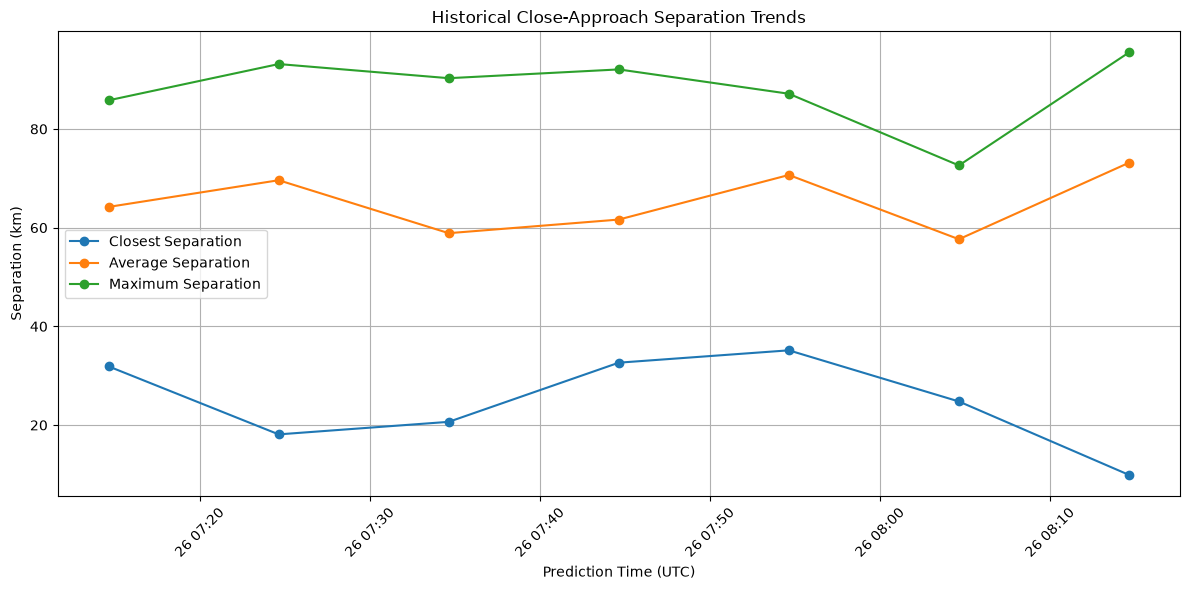

In [400]:
#Visualise historical trends

plt.figure(figsize=(12, 6))

plt.plot(
    historical_summary["prediction_time_utc"],
    historical_summary["closest_separation_km"],
    marker="o",
    label="Closest Separation"
)

plt.plot(
    historical_summary["prediction_time_utc"],
    historical_summary["average_separation_km"],
    marker="o",
    label="Average Separation"
)

plt.plot(
    historical_summary["prediction_time_utc"],
    historical_summary["maximum_separation_km"],
    marker="o",
    label="Maximum Separation"
)

plt.xlabel("Prediction Time (UTC)")
plt.ylabel("Separation (km)")
plt.title("Historical Close-Approach Separation Trends")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [401]:
#Identify repeatedly occurring close-approach pairs

# Analyse repeated close-approach pairs

historical_pair_summary = historical_data.groupby(
    "pair_key"
).agg(
    object_A_id=("object_A_id", "first"),
    object_B_id=("object_B_id", "first"),
    observation_count=("separation_km", "count"),
    minimum_separation_km=("separation_km", "min"),
    maximum_separation_km=("separation_km", "max"),
    average_separation_km=("separation_km", "mean")
).reset_index()

# Keep pairs observed at more than one timestamp
repeated_pairs = historical_pair_summary[
    historical_pair_summary["observation_count"] > 1
].sort_values(
    by="observation_count",
    ascending=False
).reset_index(drop=True)

print("Total unique candidate pairs:",
      len(historical_pair_summary))

print("Repeated candidate pairs:",
      len(repeated_pairs))

print("\nRepeated pair analysis:")
print(repeated_pairs.to_string(index=False))


Total unique candidate pairs: 32
Repeated candidate pairs: 10

Repeated pair analysis:
      pair_key  object_A_id  object_B_id  observation_count  minimum_separation_km  maximum_separation_km  average_separation_km
(33762, 34045)        33762        34045                  7               9.900489              35.143572              24.730393
(34297, 36632)        34297        36632                  7              40.636882              84.225931              58.722217
(33994, 47068)        33994        47068                  4              49.847261              79.985302              65.346641
(34273, 34547)        34273        34547                  3              53.317974              90.292265              69.425349
(34303, 37293)        34303        37293                  3              80.435137              92.070392              85.593233
(35614, 35885)        35614        35885                  3              58.502498              75.596344              64.602399
(35836, 36

In [402]:
#Examine the closest repeated pair over time

# Track the closest repeated pair over time

target_pair = (33762, 34045)

pair_history = historical_data[
    historical_data["pair_key"] == target_pair
].sort_values(
    by="prediction_time_utc"
).copy()

print("Object A:", target_pair[0])
print("Object B:", target_pair[1])

print("\nSeparation history:")
print(
    pair_history[
        ["prediction_time_utc", "separation_km"]
    ].to_string(index=False)
)


Object A: 33762
Object B: 34045

Separation history:
             prediction_time_utc  separation_km
2026-10-26 07:14:37.419912+00:00      31.886714
2026-10-26 07:24:37.419912+00:00      18.111105
2026-10-26 07:34:37.419912+00:00      20.652152
2026-10-26 07:44:37.419912+00:00      32.641414
2026-10-26 07:54:37.419912+00:00      35.143572
2026-10-26 08:04:37.419912+00:00      24.777305
2026-10-26 08:14:37.419912+00:00       9.900489


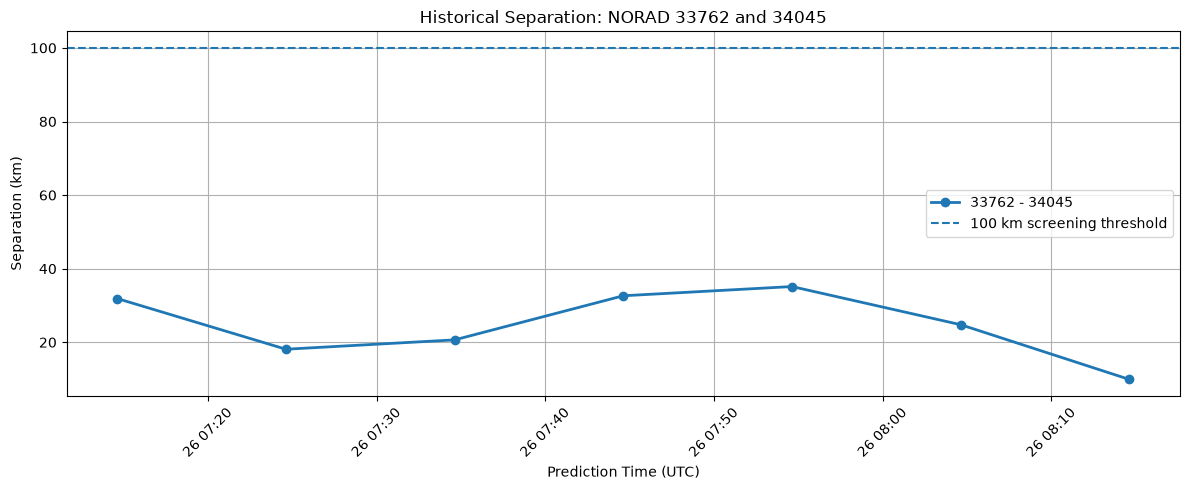

In [403]:
#Visualise the individual pairs's history

plt.figure(figsize=(12, 5))

plt.plot(
    pair_history["prediction_time_utc"],
    pair_history["separation_km"],
    marker="o",
    linewidth=2,
    label="33762 - 34045"
)

plt.axhline(
    y=100,
    linestyle="--",
    label="100 km screening threshold"
)

plt.xlabel("Prediction Time (UTC)")
plt.ylabel("Separation (km)")
plt.title("Historical Separation: NORAD 33762 and 34045")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [404]:
#Analyse relative speed and separation rate over time

# Historical motion analysis of NORAD 33762 and 34045

pair_motion_history = approach_df.sort_values(
    by="prediction_time_utc"
).copy()

print(
    pair_motion_history[
        [
            "prediction_time_utc",
            "separation_km",
            "relative_speed_km_s",
            "separation_rate_km_s",
            "motion_status"
        ]
    ].to_string(index=False)
)


             prediction_time_utc  separation_km  relative_speed_km_s  separation_rate_km_s motion_status
2026-10-26 07:14:37.419912+00:00      31.886714             0.030652             -0.021851   APPROACHING
2026-10-26 07:24:37.419912+00:00      18.111105             0.038572             -0.016940   APPROACHING
2026-10-26 07:34:37.419912+00:00      20.652152             0.033399              0.020840      RECEDING
2026-10-26 07:44:37.419912+00:00      32.641414             0.016679              0.014377      RECEDING
2026-10-26 07:54:37.419912+00:00      35.143572             0.008008             -0.006845   APPROACHING
2026-10-26 08:04:37.419912+00:00      24.777305             0.027410             -0.026211   APPROACHING
2026-10-26 08:14:37.419912+00:00       9.900489             0.037998             -0.006035   APPROACHING


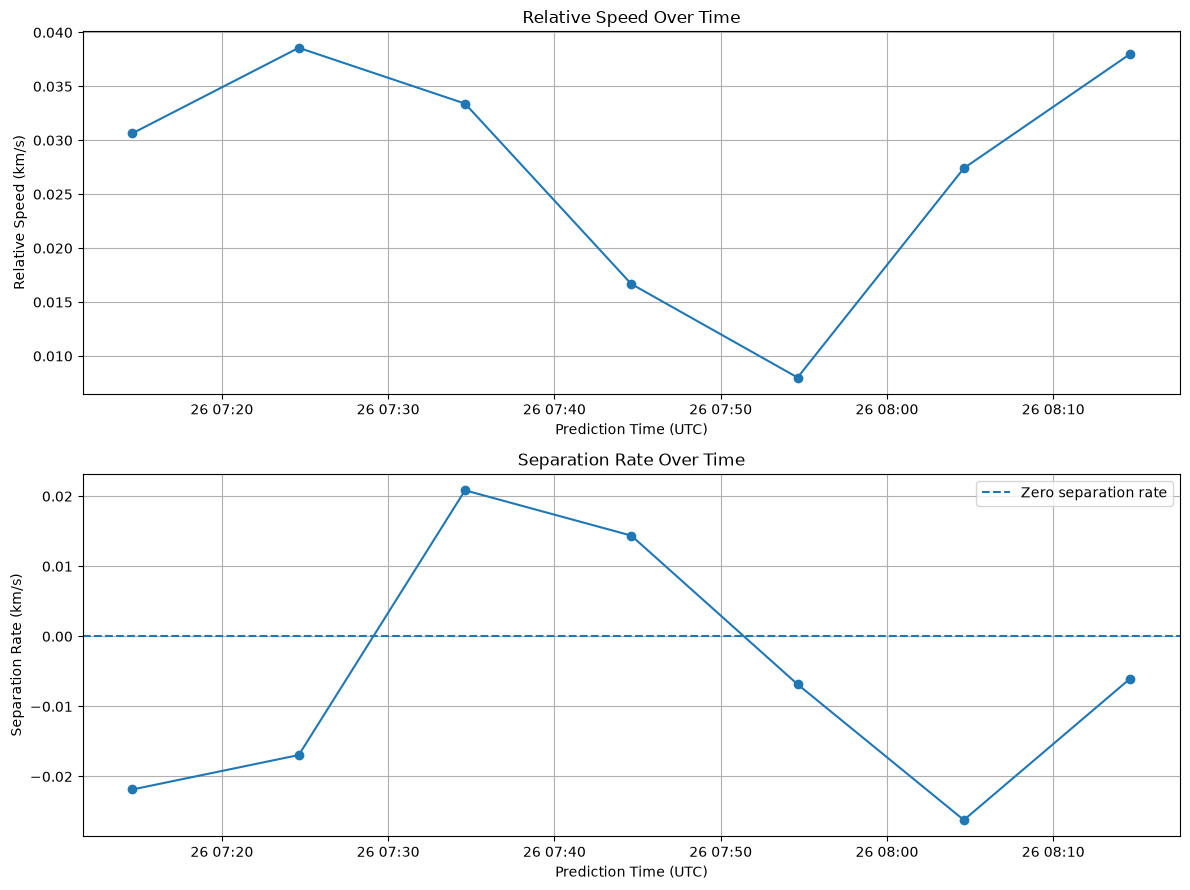

In [405]:
#Visualise relative speed and separation rate

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Relative speed chart
axes[0].plot(
    pair_motion_history["prediction_time_utc"],
    pair_motion_history["relative_speed_km_s"],
    marker="o"
)
axes[0].set_title("Relative Speed Over Time")
axes[0].set_xlabel("Prediction Time (UTC)")
axes[0].set_ylabel("Relative Speed (km/s)")
axes[0].grid(True)

# Separation rate chart
axes[1].plot(
    pair_motion_history["prediction_time_utc"],
    pair_motion_history["separation_rate_km_s"],
    marker="o"
)
axes[1].axhline(y=0, linestyle="--", label="Zero separation rate")
axes[1].set_title("Separation Rate Over Time")
axes[1].set_xlabel("Prediction Time (UTC)")
axes[1].set_ylabel("Separation Rate (km/s)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [406]:
#Calculate historical separation changes

# Calculate separation changes between consecutive timestamps

pair_history["previous_separation_km"] = (
    pair_history["separation_km"].shift(1)
)

pair_history["separation_change_km"] = (
    pair_history["separation_km"] -
    pair_history["previous_separation_km"]
)

pair_history["interval_change_status"] = np.where(
    pair_history["separation_change_km"] < 0,
    "DISTANCE_DECREASED",
    np.where(
        pair_history["separation_change_km"] > 0,
        "DISTANCE_INCREASED",
        "NO_CHANGE"
    )
)

print(
    pair_history[
        [
            "prediction_time_utc",
            "separation_km",
            "separation_change_km",
            "interval_change_status"
        ]
    ].to_string(index=False)
)


             prediction_time_utc  separation_km  separation_change_km interval_change_status
2026-10-26 07:14:37.419912+00:00      31.886714                   NaN              NO_CHANGE
2026-10-26 07:24:37.419912+00:00      18.111105            -13.775610     DISTANCE_DECREASED
2026-10-26 07:34:37.419912+00:00      20.652152              2.541047     DISTANCE_INCREASED
2026-10-26 07:44:37.419912+00:00      32.641414             11.989262     DISTANCE_INCREASED
2026-10-26 07:54:37.419912+00:00      35.143572              2.502158     DISTANCE_INCREASED
2026-10-26 08:04:37.419912+00:00      24.777305            -10.366267     DISTANCE_DECREASED
2026-10-26 08:14:37.419912+00:00       9.900489            -14.876815     DISTANCE_DECREASED


In [407]:

# Overall historical summary for the selected pair

historical_pair_overall = {
    "object_A_id": 33762,
    "object_B_id": 34045,
    "total_observations": len(pair_history),
    "starting_separation_km": pair_history["separation_km"].iloc[0],
    "ending_separation_km": pair_history["separation_km"].iloc[-1],
    "minimum_separation_km": pair_history["separation_km"].min(),
    "maximum_separation_km": pair_history["separation_km"].max(),
    "average_separation_km": pair_history["separation_km"].mean(),
    "total_distance_decreases": (
        pair_history["interval_change_status"] == "DISTANCE_DECREASED"
    ).sum(),
    "total_distance_increases": (
        pair_history["interval_change_status"] == "DISTANCE_INCREASED"
    ).sum(),
    "net_separation_change_km": (
        pair_history["separation_km"].iloc[-1] -
        pair_history["separation_km"].iloc[0]
    )
}

historical_pair_overall_df = pd.DataFrame(
    [historical_pair_overall]
)

print(historical_pair_overall_df.T.to_string())


                                     0
object_A_id               33762.000000
object_B_id               34045.000000
total_observations            7.000000
starting_separation_km       31.886714
ending_separation_km          9.900489
minimum_separation_km         9.900489
maximum_separation_km        35.143572
average_separation_km        24.730393
total_distance_decreases      3.000000
total_distance_increases      3.000000
net_separation_change_km    -21.986225


In [408]:
# Save historical analysis reports

# Save historical analysis reports

historical_summary.to_csv(
    "historical_timestamp_summary.csv",
    index=False
)

historical_pair_summary.to_csv(
    "historical_pair_summary.csv",
    index=False
)

historical_pair_overall_df.to_csv(
    "historical_closest_pair_summary.csv",
    index=False
)

print("Historical reports saved successfully!")

print("\n1. historical_timestamp_summary.csv")
print("2. historical_pair_summary.csv")
print("3. historical_closest_pair_summary.csv")


Historical reports saved successfully!

1. historical_timestamp_summary.csv
2. historical_pair_summary.csv
3. historical_closest_pair_summary.csv


In [409]:

# Verify all historical reports

import os
import pandas as pd

historical_files = [
    "historical_timestamp_summary.csv",
    "historical_pair_summary.csv",
    "historical_closest_pair_summary.csv"
]

for file in historical_files:

    print("\nFile:", file)

    if os.path.exists(file):

        check_df = pd.read_csv(file)

        print("Status: VERIFIED")
        print("Rows:", len(check_df))
        print("Columns:", len(check_df.columns))
        print("Missing values:", check_df.isnull().sum().sum())
        print("Duplicate rows:", check_df.duplicated().sum())

    else:
        print("Status: FILE NOT FOUND")



File: historical_timestamp_summary.csv
Status: VERIFIED
Rows: 7
Columns: 6
Missing values: 0
Duplicate rows: 0

File: historical_pair_summary.csv
Status: VERIFIED
Rows: 32
Columns: 7
Missing values: 0
Duplicate rows: 0

File: historical_closest_pair_summary.csv
Status: VERIFIED
Rows: 1
Columns: 11
Missing values: 0
Duplicate rows: 0


In [410]:
import pandas as pd 

debris_omm_json = pd.read_json("debris_omm.json")
print(debris_omm_json.shape)
print(debris_omm_json.describe())
print(debris_omm_json.head(10))

(580, 17)
       MEAN_MOTION  ECCENTRICITY  INCLINATION  RA_OF_ASC_NODE  \
count   580.000000    580.000000   580.000000      580.000000   
mean     14.462382      0.009478    74.005825      175.037358   
std       0.402274      0.010984     0.074672      101.206668   
min      13.208446      0.000509    73.540400        0.462200   
25%      14.334912      0.002303    73.992550       84.426525   
50%      14.494978      0.005330    74.024700      174.282650   
75%      14.681410      0.010583    74.041025      260.482000   
max      15.783141      0.056772    74.267300      358.483900   

       ARG_OF_PERICENTER  MEAN_ANOMALY  EPHEMERIS_TYPE  NORAD_CAT_ID  \
count         580.000000    580.000000           580.0    580.000000   
mean          174.326847    172.021619             0.0  35785.603448   
std           107.299592    107.176692             0.0   2514.077627   
min             0.184400      0.657100             0.0  33757.000000   
25%            79.252550     77.734150      

In [411]:
# Check the original orbital dataset

print("Dataset shape:", debris_omm_json.shape)

print("\nColumn names:")
print(debris_omm_json.columns.tolist())

print("\nData types:")
print(debris_omm_json.dtypes)

print("\nMissing values:")
print(debris_omm_json.isnull().sum())

print("\nDuplicate rows:",
      debris_omm_json.duplicated().sum())

print("\nUnique NORAD IDs:",
      debris_omm_json["NORAD_CAT_ID"].nunique())

print("\nDuplicate NORAD IDs:",
      debris_omm_json["NORAD_CAT_ID"].duplicated().sum())

Dataset shape: (580, 17)

Column names:
['OBJECT_NAME', 'OBJECT_ID', 'EPOCH', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'ARG_OF_PERICENTER', 'MEAN_ANOMALY', 'EPHEMERIS_TYPE', 'CLASSIFICATION_TYPE', 'NORAD_CAT_ID', 'ELEMENT_SET_NO', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT']

Data types:
OBJECT_NAME                str
OBJECT_ID                  str
EPOCH                      str
MEAN_MOTION            float64
ECCENTRICITY           float64
INCLINATION            float64
RA_OF_ASC_NODE         float64
ARG_OF_PERICENTER      float64
MEAN_ANOMALY           float64
EPHEMERIS_TYPE           int64
CLASSIFICATION_TYPE        str
NORAD_CAT_ID             int64
ELEMENT_SET_NO           int64
REV_AT_EPOCH             int64
BSTAR                  float64
MEAN_MOTION_DOT        float64
MEAN_MOTION_DDOT         int64
dtype: object

Missing values:
OBJECT_NAME            0
OBJECT_ID              0
EPOCH                  0
MEAN_MOTION            0
ECCENTRICIT

In [412]:
# Check orbital element ranges

print("ECCENTRICITY:")
print(debris_omm_json["ECCENTRICITY"].describe())

print("\nINCLINATION:")
print(debris_omm_json["INCLINATION"].describe())

print("\nMEAN MOTION:")
print(debris_omm_json["MEAN_MOTION"].describe())

print("\nBSTAR:")
print(debris_omm_json["BSTAR"].describe())

print("\nCheck invalid orbital values:")

print("Eccentricity outside [0, 1):",
      ((debris_omm_json["ECCENTRICITY"] < 0) |
       (debris_omm_json["ECCENTRICITY"] >= 1)).sum())

print("Inclination outside [0, 180]:",
      ((debris_omm_json["INCLINATION"] < 0) |
       (debris_omm_json["INCLINATION"] > 180)).sum())

print("Non-positive mean motion:",
      (debris_omm_json["MEAN_MOTION"] <= 0).sum())

print("Non-finite numeric values:",
      (~debris_omm_json.select_dtypes(include="number")
       .apply(lambda col: col.map(lambda x: pd.notna(x) and abs(x) != float("inf")))
       .all()).sum())

ECCENTRICITY:
count    580.000000
mean       0.009478
std        0.010984
min        0.000509
25%        0.002303
50%        0.005330
75%        0.010583
max        0.056772
Name: ECCENTRICITY, dtype: float64

INCLINATION:
count    580.000000
mean      74.005825
std        0.074672
min       73.540400
25%       73.992550
50%       74.024700
75%       74.041025
max       74.267300
Name: INCLINATION, dtype: float64

MEAN MOTION:
count    580.000000
mean      14.462382
std        0.402274
min       13.208446
25%       14.334912
50%       14.494978
75%       14.681410
max       15.783141
Name: MEAN_MOTION, dtype: float64

BSTAR:
count    580.000000
mean       0.000777
std        0.000830
min        0.000024
25%        0.000282
50%        0.000524
75%        0.000990
max        0.007438
Name: BSTAR, dtype: float64

Check invalid orbital values:
Eccentricity outside [0, 1): 0
Inclination outside [0, 180]: 0
Non-positive mean motion: 0
Non-finite numeric values: 0


In [413]:
# Convert EPOCH into UTC datetime

debris_omm_json["EPOCH"] = pd.to_datetime(
    debris_omm_json["EPOCH"],
    utc=True
)

# Reference time: original propagation start
reference_time = pd.Timestamp(
    "2026-10-26 07:14:37",
    tz="UTC"
)

# Calculate orbital element age in hours
debris_omm_json["ELEMENT_AGE_HOURS"] = (
    reference_time - debris_omm_json["EPOCH"]
).dt.total_seconds() / 3600

# Display results
print("Epoch conversion successful:",
      debris_omm_json["EPOCH"].notna().all())

print("\nOrbital element age statistics:")
print(debris_omm_json["ELEMENT_AGE_HOURS"].describe())

print("\nFuture epochs:")
print((debris_omm_json["ELEMENT_AGE_HOURS"] < 0).sum())

print("\nObjects by age category:")
print(
    pd.cut(
        debris_omm_json["ELEMENT_AGE_HOURS"],
        bins=[-float("inf"), 24, 72, float("inf")],
        labels=["RECENT", "REVIEW_RECOMMENDED", "STALE_REVIEW_REQUIRED"]
    ).value_counts()
)

Epoch conversion successful: True

Orbital element age statistics:
count    580.000000
mean     116.848234
std       72.525905
min       73.477716
25%       82.358870
50%       93.162599
75%      119.430490
max      707.419700
Name: ELEMENT_AGE_HOURS, dtype: float64

Future epochs:
0

Objects by age category:
ELEMENT_AGE_HOURS
STALE_REVIEW_REQUIRED    580
RECENT                     0
REVIEW_RECOMMENDED         0
Name: count, dtype: int64


In [414]:
# Identify newest and oldest orbital elements

print("5 NEWEST ORBITAL ELEMENTS")
print(
    debris_omm_json[
        ["NORAD_CAT_ID", "OBJECT_NAME", "EPOCH", "ELEMENT_AGE_HOURS"]
    ]
    .sort_values("ELEMENT_AGE_HOURS")
    .head(5)
)

print("\n5 OLDEST ORBITAL ELEMENTS")
print(
    debris_omm_json[
        ["NORAD_CAT_ID", "OBJECT_NAME", "EPOCH", "ELEMENT_AGE_HOURS"]
    ]
    .sort_values("ELEMENT_AGE_HOURS", ascending=False)
    .head(5)
)

5 NEWEST ORBITAL ELEMENTS
     NORAD_CAT_ID      OBJECT_NAME                            EPOCH  \
45          33899  COSMOS 2251 DEB 2026-10-23 05:45:57.223296+00:00   
96          34014  COSMOS 2251 DEB 2026-10-23 05:38:49.886304+00:00   
135         34139  COSMOS 2251 DEB 2026-10-23 05:31:34.780224+00:00   
33          33835  COSMOS 2251 DEB 2026-10-23 05:26:13.400736+00:00   
141         34276  COSMOS 2251 DEB 2026-10-23 05:16:53.514912+00:00   

     ELEMENT_AGE_HOURS  
45           73.477716  
96           73.596420  
135          73.717283  
33           73.806555  
141          73.962079  

5 OLDEST ORBITAL ELEMENTS
     NORAD_CAT_ID      OBJECT_NAME                            EPOCH  \
497         37531  COSMOS 2251 DEB 2026-09-26 19:49:26.080320+00:00   
278         34918  COSMOS 2251 DEB 2026-09-30 07:54:19.918080+00:00   
414         35987  COSMOS 2251 DEB 2026-10-01 07:49:35.064192+00:00   
320         35071  COSMOS 2251 DEB 2026-10-03 07:13:37.739136+00:00   
539         384

In [415]:
# Compare original OMM and propagated datasets

omm_ids = set(debris_omm_json["NORAD_CAT_ID"])

propagated_ids = set(df["NORAD_CAT_ID"])

print("OMM unique objects:", len(omm_ids))
print("Propagated unique objects:", len(propagated_ids))

print("\nObjects in OMM but missing from propagation:",
      len(omm_ids - propagated_ids))

print("Objects in propagation but missing from OMM:",
      len(propagated_ids - omm_ids))

print("\nAre both datasets using exactly the same objects?",
      omm_ids == propagated_ids)

if omm_ids - propagated_ids:
    print("\nMissing from propagation:", sorted(omm_ids - propagated_ids))

if propagated_ids - omm_ids:
    print("\nNot present in OMM:", sorted(propagated_ids - omm_ids))

OMM unique objects: 580
Propagated unique objects: 580

Objects in OMM but missing from propagation: 0
Objects in propagation but missing from OMM: 0

Are both datasets using exactly the same objects? True


In [416]:
#Verify orbital element consistency
# Compare original OMM epochs with propagated dataset epochs

omm_check = debris_omm_json[
    ["NORAD_CAT_ID", "OBJECT_NAME", "EPOCH"]
].copy()

prop_check = df[
    ["NORAD_CAT_ID", "OBJECT_NAME", "ELEMENT_EPOCH"]
].drop_duplicates(subset="NORAD_CAT_ID").copy()

# Convert both epoch columns to UTC
omm_check["EPOCH"] = pd.to_datetime(
    omm_check["EPOCH"], utc=True
)

prop_check["ELEMENT_EPOCH"] = pd.to_datetime(
    prop_check["ELEMENT_EPOCH"], utc=True
)

# Match records using NORAD ID
epoch_comparison = omm_check.merge(
    prop_check,
    on="NORAD_CAT_ID",
    suffixes=("_OMM", "_PROPAGATED"),
    how="inner"
)

# Check epoch equality
epoch_comparison["EPOCH_MATCH"] = (
    epoch_comparison["EPOCH"] ==
    epoch_comparison["ELEMENT_EPOCH"]
)

# Check object-name equality
epoch_comparison["NAME_MATCH"] = (
    epoch_comparison["OBJECT_NAME_OMM"] ==
    epoch_comparison["OBJECT_NAME_PROPAGATED"]
)

print("Matched objects:", len(epoch_comparison))

print("\nEpoch matches:",
      epoch_comparison["EPOCH_MATCH"].sum())

print("Epoch mismatches:",
      (~epoch_comparison["EPOCH_MATCH"]).sum())

print("\nObject-name matches:",
      epoch_comparison["NAME_MATCH"].sum())

print("Object-name mismatches:",
      (~epoch_comparison["NAME_MATCH"]).sum())

print("\nEpoch mismatch examples:")
print(
    epoch_comparison.loc[
        ~epoch_comparison["EPOCH_MATCH"]
    ].head(10)
)

Matched objects: 580

Epoch matches: 580
Epoch mismatches: 0

Object-name matches: 580
Object-name mismatches: 0

Epoch mismatch examples:
Empty DataFrame
Columns: [NORAD_CAT_ID, OBJECT_NAME_OMM, EPOCH, OBJECT_NAME_PROPAGATED, ELEMENT_EPOCH, EPOCH_MATCH, NAME_MATCH]
Index: []


In [417]:
#Verify whether each object has exactly seven propagated observations
# Check prediction completeness for every object

prediction_counts = (
    df.groupby("NORAD_CAT_ID")["PREDICTION_TIME_UTC"]
    .agg(["count", "nunique"])
)

print("Total objects:", len(prediction_counts))

print("\nObjects with exactly 7 records:",
      (prediction_counts["count"] == 7).sum())

print("Objects with fewer than 7 records:",
      (prediction_counts["count"] < 7).sum())

print("Objects with more than 7 records:",
      (prediction_counts["count"] > 7).sum())

print("Objects with duplicate timestamps:",
      (prediction_counts["count"] != prediction_counts["nunique"]).sum())

print("\nPrediction count distribution:")
print(prediction_counts["count"].value_counts().sort_index())

Total objects: 580

Objects with exactly 7 records: 580
Objects with fewer than 7 records: 0
Objects with more than 7 records: 0
Objects with duplicate timestamps: 0

Prediction count distribution:
count
7    580
Name: count, dtype: int64


In [418]:
# Check prediction timestamp coverage

prediction_times = (
    pd.to_datetime(df["PREDICTION_TIME_UTC"], utc=True)
    .drop_duplicates()
    .sort_values()
)

print("Total unique timestamps:", len(prediction_times))

print("\nPrediction timestamps:")
print(prediction_times.to_list())

print("\nTime intervals in minutes:")
print(
    prediction_times.diff().dt.total_seconds().div(60).dropna().tolist()
)

print("\nPrediction offsets:")
print(
    sorted(df["MINUTES_FROM_START"].unique())
)

Total unique timestamps: 7

Prediction timestamps:
[Timestamp('2026-10-26 07:14:37.419912+0000', tz='UTC'), Timestamp('2026-10-26 07:24:37.419912+0000', tz='UTC'), Timestamp('2026-10-26 07:34:37.419912+0000', tz='UTC'), Timestamp('2026-10-26 07:44:37.419912+0000', tz='UTC'), Timestamp('2026-10-26 07:54:37.419912+0000', tz='UTC'), Timestamp('2026-10-26 08:04:37.419912+0000', tz='UTC'), Timestamp('2026-10-26 08:14:37.419912+0000', tz='UTC')]

Time intervals in minutes:
[10.0, 10.0, 10.0, 10.0, 10.0, 10.0]

Prediction offsets:
[np.int64(0), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60)]


In [419]:
# Validate propagated position and velocity values

position_cols = [
    "X_TEME_KM",
    "Y_TEME_KM",
    "Z_TEME_KM"
]

velocity_cols = [
    "VX_TEME_KM_S",
    "VY_TEME_KM_S",
    "VZ_TEME_KM_S"
]

print("Position non-finite values:")
print(
    (~df[position_cols].apply(
        lambda col: pd.to_numeric(col, errors="coerce").map(
            lambda x: pd.notna(x) and abs(x) != float("inf")
        )
    )).sum()
)

print("\nVelocity non-finite values:")
print(
    (~df[velocity_cols].apply(
        lambda col: pd.to_numeric(col, errors="coerce").map(
            lambda x: pd.notna(x) and abs(x) != float("inf")
        )
    )).sum()
)

# Calculate position magnitude and speed
position_magnitude = (
    df[position_cols] ** 2
).sum(axis=1) ** 0.5

velocity_magnitude = (
    df[velocity_cols] ** 2
).sum(axis=1) ** 0.5

print("\nPosition magnitude statistics (km):")
print(position_magnitude.describe())

print("\nVelocity magnitude statistics (km/s):")
print(velocity_magnitude.describe())

print("\nZero position records:",
      (position_magnitude == 0).sum())

print("Zero velocity records:",
      (velocity_magnitude == 0).sum())

Position non-finite values:
X_TEME_KM    0
Y_TEME_KM    0
Z_TEME_KM    0
dtype: int64

Velocity non-finite values:
VX_TEME_KM_S    0
VY_TEME_KM_S    0
VZ_TEME_KM_S    0
dtype: int64

Position magnitude statistics (km):
count    4060.000000
mean     7120.818593
std       156.798862
min      6503.691628
25%      7037.360717
50%      7104.500428
75%      7158.504663
max      7990.181698
dtype: float64

Velocity magnitude statistics (km/s):
count    4060.000000
mean        7.480752
std         0.104430
min         6.851671
25%         7.457336
50%         7.497206
75%         7.538233
max         7.833845
dtype: float64

Zero position records: 0
Zero velocity records: 0


In [420]:
# Identify objects with low orbital radius

radius_check = df.copy()

radius_check["POSITION_MAGNITUDE_KM"] = (
    radius_check["X_TEME_KM"]**2
    + radius_check["Y_TEME_KM"]**2
    + radius_check["Z_TEME_KM"]**2
)**0.5

object_radius_summary = (
    radius_check.groupby(
        ["NORAD_CAT_ID", "OBJECT_NAME"]
    )["POSITION_MAGNITUDE_KM"]
    .agg(["min", "max", "mean"])
    .reset_index()
)

# Approximate altitude using mean Earth radius
object_radius_summary["MIN_ALTITUDE_KM"] = (
    object_radius_summary["min"] - 6371
)

print("Objects with minimum radius below 6700 km:")

print(
    object_radius_summary[
        object_radius_summary["min"] < 6700
    ].sort_values("min")
)

print("\nFive objects with the lowest minimum radius:")

print(
    object_radius_summary.sort_values("min").head(5)
)

Objects with minimum radius below 6700 km:
     NORAD_CAT_ID      OBJECT_NAME          min          max         mean  \
67          33939  COSMOS 2251 DEB  6503.691628  6527.589501  6515.380219   
539         38487  COSMOS 2251 DEB  6653.336997  6681.917934  6666.245930   

     MIN_ALTITUDE_KM  
67        132.691628  
539       282.336997  

Five objects with the lowest minimum radius:
     NORAD_CAT_ID      OBJECT_NAME          min          max         mean  \
67          33939  COSMOS 2251 DEB  6503.691628  6527.589501  6515.380219   
539         38487  COSMOS 2251 DEB  6653.336997  6681.917934  6666.245930   
23          33818  COSMOS 2251 DEB  6731.186748  6760.439105  6744.711877   
352         35602  COSMOS 2251 DEB  6757.974174  6845.388128  6808.937270   
25          33821  COSMOS 2251 DEB  6775.123691  6829.650251  6804.730773   

     MIN_ALTITUDE_KM  
67        132.691628  
539       282.336997  
23        360.186748  
352       386.974174  
25        404.123691  


In [421]:
# Check SGP4 propagation completeness by object and timestamp

expected_records = 580 * 7
actual_records = len(df)

print("Expected records:", expected_records)
print("Actual records:", actual_records)
print("Missing records:", expected_records - actual_records)

print("\nRecords per timestamp:")
print(
    df.groupby("MINUTES_FROM_START")
      .size()
      .sort_index()
)

print("\nUnique offsets:")
print(sorted(df["MINUTES_FROM_START"].unique()))

Expected records: 4060
Actual records: 4060
Missing records: 0

Records per timestamp:
MINUTES_FROM_START
0     580
10    580
20    580
30    580
40    580
50    580
60    580
dtype: int64

Unique offsets:
[np.int64(0), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60)]


In [422]:
# Inspect SGP4 propagation and error-handling code

with open("orbital_propagation1.py", "r", encoding="utf-8") as file:
    script_lines = file.readlines()

for line_number, line in enumerate(script_lines, start=1):
    if any(
        keyword in line.lower()
        for keyword in [
            "sat.sgp4",
            "error",
            "sgp4_errors",
            "if error",
            "position",
            "velocity",
            "writer"
        ]
    ):
        start = max(0, line_number - 3)
        end = min(len(script_lines), line_number + 3)

        print(f"\n--- Lines {start + 1} to {end} ---")

        for i in range(start, end):
            print(f"{i + 1}: {script_lines[i].rstrip()}")


--- Lines 4 to 9 ---
4: from datetime import datetime, timedelta, timezone
5: 
6: from sgp4.api import Satrec, jday, SGP4_ERRORS
7: from sgp4.omm import initialize
8: 
9: # --------------------------------------------------

--- Lines 17 to 22 ---
17: OUTPUT_FILE = DATA_DIR / "propagated_debris_new.csv"
18: 
19: # Predict positions at these offsets from the current UTC time
20: TIME_OFFSETS_MINUTES = [0, 10, 20, 30, 40, 50, 60]
21: 
22: print("OrbiX - Orbital Propagation")

--- Lines 28 to 33 ---
28: 
29: if not INPUT_FILE.exists():
30:     raise FileNotFoundError(
31:         f"Orbital data not found: {INPUT_FILE.resolve()}"
32:     )
33: 

--- Lines 36 to 41 ---
36: 
37: if not isinstance(orbital_records, list):
38:     raise ValueError(
39:         "Expected debris_omm.json to contain a list of orbital records."
40:     )
41: 

--- Lines 46 to 51 ---
46: 
47: # --------------------------------------------------
48: # 2. Initialize tracking results and error counters
49: # ---------

In [423]:
from pathlib import Path

project_folder = Path.cwd()

print("Notebook working directory:")
print(project_folder)

print("\nSearching for the new CSV...")

matches = list(
    project_folder.rglob("propagated_debris_new.csv")
)

for file_path in matches:
    print(file_path.resolve())

Notebook working directory:
c:\Users\ASUS\OneDrive\Desktop\New folder\.venv-1

Searching for the new CSV...


C:\Users\ASUS\OneDrive\Desktop\New folder\.venv-1\propagated_debris_new.csv


In [424]:
# Load the newly generated propagation dataset

new_propagated_df = pd.read_csv("propagated_debris_new.csv")

print("New dataset shape:", new_propagated_df.shape)

print(
    "Unique NORAD objects:",
    new_propagated_df["NORAD_CAT_ID"].nunique()
)

print(
    "Total prediction records:",
    len(new_propagated_df)
)

print(
    "\nIs NORAD 33939 present?",
    33939 in new_propagated_df["NORAD_CAT_ID"].values
)

print("\nRecords per object:")
print(
    new_propagated_df.groupby("NORAD_CAT_ID")
    .size()
    .value_counts()
    .sort_index()
)

New dataset shape: (4053, 11)
Unique NORAD objects: 579
Total prediction records: 4053

Is NORAD 33939 present? False

Records per object:
7    579
Name: count, dtype: int64


In [425]:
# Compare OMM object IDs with successfully propagated object IDs

omm_ids = set(debris_omm_json["NORAD_CAT_ID"].astype(int))

propagated_ids = set(
    new_propagated_df["NORAD_CAT_ID"].astype(int)
)

missing_ids = omm_ids - propagated_ids
unexpected_ids = propagated_ids - omm_ids

print("Objects in original OMM:", len(omm_ids))
print("Objects successfully propagated:", len(propagated_ids))

print("\nObjects missing from propagation:", len(missing_ids))
print("Unexpected objects in propagation:", len(unexpected_ids))

print("\nMissing object details:")

print(
    debris_omm_json[
        debris_omm_json["NORAD_CAT_ID"].isin(missing_ids)
    ][["NORAD_CAT_ID", "OBJECT_NAME", "EPOCH"]]
)

print("\nUnexpected IDs:", unexpected_ids)

Objects in original OMM: 580
Objects successfully propagated: 579

Objects missing from propagation: 1
Unexpected objects in propagation: 0

Missing object details:
    NORAD_CAT_ID      OBJECT_NAME                            EPOCH
67         33939  COSMOS 2251 DEB 2026-10-15 14:49:08.112000+00:00

Unexpected IDs: set()


In [426]:
# Create a report for objects that failed propagation

missing_propagation_report = debris_omm_json[
    debris_omm_json["NORAD_CAT_ID"].isin(
        set(debris_omm_json["NORAD_CAT_ID"])
        - set(new_propagated_df["NORAD_CAT_ID"])
    )
][["NORAD_CAT_ID", "OBJECT_NAME", "EPOCH"]].copy()

missing_propagation_report["STATUS"] = "PROPAGATION_FAILED"

missing_propagation_report["SGP4_ERROR_CODE"] = 6

missing_propagation_report["FAILURE_REASON"] = (
    "mrt is less than 1.0 - SGP4 predicted decayed orbit"
)

print(missing_propagation_report)

    NORAD_CAT_ID      OBJECT_NAME                            EPOCH  \
67         33939  COSMOS 2251 DEB 2026-10-15 14:49:08.112000+00:00   

                STATUS  SGP4_ERROR_CODE  \
67  PROPAGATION_FAILED                6   

                                       FAILURE_REASON  
67  mrt is less than 1.0 - SGP4 predicted decayed ...  


In [427]:
from pathlib import Path

script_path = Path("orbital_propagation1.py")

print("Script exists:", script_path.exists())

if script_path.exists():
    lines = script_path.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if any(word in line.lower() for word in [
            "incomplete",
            "successful_object_ids",
            "expected_predictions"
        ]):
            start = max(0, i - 4)
            end = min(len(lines), i + 6)

            print(f"\n--- Lines {start + 1} to {end} ---")

            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")

Script exists: True

--- Lines 54 to 63 ---
54: failed_predictions = 0
55: sgp4_error_counts = {}
56: 
57: # Track objects that produced at least one successful prediction
58: successful_object_ids = set()
59: 
60: # --------------------------------------------------
61: # 3. Propagate each object's orbit
62: # --------------------------------------------------
63: 

--- Lines 162 to 171 ---
162:                 "VY_TEME_KM_S": velocity[1],
163:                 "VZ_TEME_KM_S": velocity[2],
164:             })
165: 
166:             successful_object_ids.add(object_id)
167: 
168:     except Exception as error:
169: 
170:         failed_objects += 1
171: 

--- Lines 224 to 233 ---
224: # --------------------------------------------------
225: # 5. Check prediction completeness
226: # --------------------------------------------------
227: 
228: expected_predictions = (
229:     len(orbital_records) * len(TIME_OFFSETS_MINUTES)
230: )
231: 
232: actual_predictions = len(results)
233: 

---

In [428]:
from pathlib import Path

required_files = [
    "propagated_debris.csv",
    "propagated_debris_new.csv",
    "final_screening_quality_report.csv",
    "dashboard_summary.csv",
    "project_overview.csv",
    "orbital_data_quality_report.csv",
    "threshold_comparison_report.csv",
    "motion_status_summary.csv",
    "historical_timestamp_summary.csv",
    "historical_pair_summary.csv",
    "historical_closest_pair_summary.csv"
]

print("Project folder:", Path.cwd())
print("\nFINAL FILE AUDIT")
print("-" * 65)

for filename in required_files:
    path = Path(filename)

    if path.exists():
        print(f"FOUND    | {filename} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING  | {filename}")

Project folder: c:\Users\ASUS\OneDrive\Desktop\New folder\.venv-1

FINAL FILE AUDIT
-----------------------------------------------------------------
FOUND    | propagated_debris.csv | 807,961 bytes
FOUND    | propagated_debris_new.csv | 806,509 bytes
FOUND    | final_screening_quality_report.csv | 12,023 bytes
FOUND    | dashboard_summary.csv | 101 bytes
FOUND    | project_overview.csv | 382 bytes
FOUND    | orbital_data_quality_report.csv | 105,315 bytes
FOUND    | threshold_comparison_report.csv | 358 bytes
FOUND    | motion_status_summary.csv | 247 bytes
FOUND    | historical_timestamp_summary.csv | 785 bytes
FOUND    | historical_pair_summary.csv | 2,852 bytes
FOUND    | historical_closest_pair_summary.csv | 358 bytes


In [429]:
import pandas as pd
from pathlib import Path

report_files = [
    "final_screening_quality_report.csv",
    "dashboard_summary.csv",
    "project_overview.csv",
    "orbital_data_quality_report.csv",
    "threshold_comparison_report.csv",
    "motion_status_summary.csv",
    "historical_timestamp_summary.csv",
    "historical_pair_summary.csv",
    "historical_closest_pair_summary.csv"
]

print("FINAL REPORT VALIDATION")
print("=" * 75)

for filename in report_files:

    report = pd.read_csv(filename)

    print(f"\nFile: {filename}")
    print("Rows:", len(report))
    print("Columns:", len(report.columns))
    print("Missing values:", report.isna().sum().sum())
    print("Duplicate rows:", report.duplicated().sum())

FINAL REPORT VALIDATION

File: final_screening_quality_report.csv
Rows: 32
Columns: 22
Missing values: 0
Duplicate rows: 0

File: dashboard_summary.csv
Rows: 1
Columns: 6
Missing values: 0
Duplicate rows: 0

File: project_overview.csv
Rows: 1
Columns: 13
Missing values: 0
Duplicate rows: 0

File: orbital_data_quality_report.csv
Rows: 580
Columns: 11
Missing values: 0
Duplicate rows: 0

File: threshold_comparison_report.csv
Rows: 4
Columns: 7
Missing values: 0
Duplicate rows: 0

File: motion_status_summary.csv
Rows: 2
Columns: 5
Missing values: 0
Duplicate rows: 0

File: historical_timestamp_summary.csv
Rows: 7
Columns: 6
Missing values: 0
Duplicate rows: 0

File: historical_pair_summary.csv
Rows: 32
Columns: 7
Missing values: 0
Duplicate rows: 0

File: historical_closest_pair_summary.csv
Rows: 1
Columns: 11
Missing values: 0
Duplicate rows: 0


In [430]:
import pandas as pd

dashboard = pd.read_csv("dashboard_summary.csv")
overview = pd.read_csv("project_overview.csv")

print("========== DASHBOARD SUMMARY ==========")
print(dashboard.to_string(index=False))

print("\n========== PROJECT OVERVIEW ==========")
print(overview.to_string(index=False))

========== DASHBOARD SUMMARY ==========
 total_candidate_pairs  priority_1  priority_2  priority_3  monitor  data_review_required
                    32           1           2           9       20                    32

========== PROJECT OVERVIEW ==========
 total_objects  total_prediction_timestamps  total_possible_pairs_per_timestamp  screening_threshold_km  total_candidate_observations  total_unique_candidate_pairs  closest_sampled_separation_km  highest_relative_speed_km_s  priority_1_pairs  priority_2_pairs  priority_3_pairs  monitor_pairs  data_review_required_pairs
           580                            7                              167910                     100                            58                            32                       9.900489                    14.530746                 1                 2                 9             20                          32


In [433]:
screening = pd.read_csv("final_screening_quality_report.csv")

print("Available columns:")
for i, column in enumerate(screening.columns, start=1):
    print(i, column)

Available columns:
1 object_A_id
2 object_B_id
3 object_A_name
4 object_B_name
5 prediction_time_utc
6 separation_km
7 relative_speed_km_s
8 separation_rate_km_s
9 motion_status
10 observation_count
11 separation_category
12 speed_category
13 review_priority
14 speed_review_flag
15 object_A_element_age_hours
16 object_B_element_age_hours
17 object_A_data_quality
18 object_B_data_quality
19 object_A_position_quality
20 object_B_position_quality
21 pair_data_quality
22 overall_quality_status


In [434]:
# Verify the final screening report

screening = pd.read_csv("final_screening_quality_report.csv")

print("PRIORITY DISTRIBUTION")
print(screening["review_priority"].value_counts())

print("\nOVERALL DATA QUALITY DISTRIBUTION")
print(screening["overall_quality_status"].value_counts())

print("\nTOTAL SCREENING RECORDS:", len(screening))

print("\nUNIQUE OBJECT PAIRS:", screening[
    ["object_A_id", "object_B_id"]
].drop_duplicates().shape[0])

PRIORITY DISTRIBUTION
review_priority
MONITOR       20
PRIORITY_3     9
PRIORITY_2     2
PRIORITY_1     1
Name: count, dtype: int64

OVERALL DATA QUALITY DISTRIBUTION
overall_quality_status
DATA_REVIEW_REQUIRED    32
Name: count, dtype: int64

TOTAL SCREENING RECORDS: 32

UNIQUE OBJECT PAIRS: 32


In [435]:
historical_files = [
    "historical_timestamp_summary.csv",
    "historical_pair_summary.csv",
    "historical_closest_pair_summary.csv"
]

for file in historical_files:
    report = pd.read_csv(file)

    print("\n" + "=" * 60)
    print("FILE:", file)
    print("Shape:", report.shape)
    print("Columns:", report.columns.tolist())
    print("Missing values:", report.isnull().sum().sum())
    print("Duplicate rows:", report.duplicated().sum())
    print("\nFirst rows:")
    print(report.head(3).to_string(index=False))


FILE: historical_timestamp_summary.csv
Shape: (7, 6)
Columns: ['prediction_time_utc', 'candidate_observations', 'unique_candidate_pairs', 'closest_separation_km', 'average_separation_km', 'maximum_separation_km']
Missing values: 0
Duplicate rows: 0

First rows:
             prediction_time_utc  candidate_observations  unique_candidate_pairs  closest_separation_km  average_separation_km  maximum_separation_km
2026-10-26 07:14:37.419912+00:00                       6                       6              31.886714              64.208613              85.810514
2026-10-26 07:24:37.419912+00:00                      12                      12              18.111105              69.614969              93.158093
2026-10-26 07:34:37.419912+00:00                      10                      10              20.652152              58.885742              90.292265

FILE: historical_pair_summary.csv
Shape: (32, 7)
Columns: ['pair_key', 'object_A_id', 'object_B_id', 'observation_count', 'minimum_separ

In [436]:
#Verify threshold and motion reports
threshold_report = pd.read_csv("threshold_comparison_report.csv")
motion_report = pd.read_csv("motion_status_summary.csv")

print("THRESHOLD COMPARISON REPORT")
print(threshold_report.to_string(index=False))

print("\nShape:", threshold_report.shape)
print("Missing values:", threshold_report.isnull().sum().sum())
print("Duplicate rows:", threshold_report.duplicated().sum())

print("\n" + "=" * 60)
print("MOTION STATUS SUMMARY")
print(motion_report.to_string(index=False))

print("\nShape:", motion_report.shape)
print("Missing values:", motion_report.isnull().sum().sum())
print("Duplicate rows:", motion_report.duplicated().sum())

THRESHOLD COMPARISON REPORT
 threshold_km  minimum_candidates  maximum_candidates  average_candidates  total_observations  unique_candidate_pairs  percentage_of_pairs
           50                   1                   4            1.857143                  13                       5             0.002978
          100                   5                  12            8.285714                  58                      32             0.019058
          200                  28                  41           34.428571                 241                     166             0.098862
          500                 222                 301          258.285714                1808                    1245             0.741469

Shape: (4, 7)
Missing values: 0
Duplicate rows: 0

MOTION STATUS SUMMARY
motion_status  pair_count  average_separation_km  average_relative_speed_km_s  average_separation_rate_km_s
  APPROACHING          12              58.073126                     2.969662                  

In [438]:
print("DATA QUALITY DISTRIBUTION")
print(quality["data_quality_status"].value_counts())

print("\nPOSITION QUALITY DISTRIBUTION")
print(quality["position_quality_status"].value_counts())

print("\nUNIQUE NORAD OBJECTS:")
print(quality["norad_cat_id"].nunique())

print("\nLOW POSITION FLAGS:")
print(quality["low_position_flag"].value_counts())

print("\nELEMENT AGE SUMMARY (HOURS):")
print(quality["element_age_hours"].describe())

DATA QUALITY DISTRIBUTION
data_quality_status
STALE_REVIEW_REQUIRED    580
Name: count, dtype: int64

POSITION QUALITY DISTRIBUTION
position_quality_status
NORMAL_POSITION_RANGE    578
LOW_POSITION_REVIEW        2
Name: count, dtype: int64

UNIQUE NORAD OBJECTS:
580

LOW POSITION FLAGS:
low_position_flag
False    578
True       2
Name: count, dtype: int64

ELEMENT AGE SUMMARY (HOURS):
count    580.000000
mean     116.848351
std       72.525905
min       73.477832
25%       82.358986
50%       93.162715
75%      119.430607
max      707.419817
Name: element_age_hours, dtype: float64
